# Thailand Landslide Susceptibility Dataset — Recurrence-Aware Version

This notebook creates a reproducible Thailand landslide-susceptibility dataset from the **56,177-record Department of Mineral Resources (DMR) landslide inventory** while preserving repeated coordinates as potentially meaningful record-frequency / recurrence information.

**Final workflow**

1. Preserve the complete original Thailand DMR inventory as an event-level master dataset.
2. Validate CRS, geometry, coordinate coverage, and repeated landslide locations.
3. Assign every source record a stable `location_id`.
4. Build a unique-location landslide inventory while retaining `landslide_count`, recurrence-proxy classes, and an optional recurrence weight.
5. Use **one row per unique location** for the main susceptibility model so repeatedly recorded locations do not dominate the classifier.
6. Keep all original duplicate/event rows in a separate event-level table for recurrence/frequency analysis.
7. Build a Thailand study-area boundary and a common 30 m projected DEM grid.
8. Derive terrain and hydrological factors from the DEM.
9. Add SoilGrids 2.0, ESA WorldCover 2021, and GLiM geology where available.
10. Generate a balanced set of pseudo-absence points inside Thailand, outside a 1 km exclusion buffer around **all known unique landslide locations**, and only where the DEM is valid.
11. Sample all available conditioning factors at landslide and pseudo-absence locations.
12. Save both susceptibility and recurrence-ready datasets, run QC/EDA, and create leakage-safe train/test outputs.

> **Interpretation note:** exact coordinate duplicates are treated as a **record-frequency / recurrence proxy**, not automatically as confirmed independent landslide events. Repeated coordinates can also arise from coordinate rounding, multiple reports of one event, or representative mapping. Confirm the DMR metadata before describing them as true temporal recurrence.


## 0. Packages

In [1]:
! pip install -U geopandas rasterio pyogrio shapely pyproj pandas numpy osmnx whitebox pyarrow requests matplotlib seaborn scikit-learn statsmodels joblib

! pip install elevation



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\PCC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\PCC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
# 1 — Imports

from pathlib import Path
from datetime import datetime, timezone
import json
import math
import time
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask as rio_mask
from rasterio.warp import calculate_default_transform, reproject, Resampling
from shapely.geometry import Point
from shapely.prepared import prep
import requests

warnings.filterwarnings("ignore", category=UserWarning)

print("GeoPandas:", gpd.__version__)
print("Rasterio :", rasterio.__version__)


GeoPandas: 1.1.4
Rasterio : 1.4.4


In [41]:
# 2 — Configuration

# Notebook is inside /notebooks, so project root is one level above.
PROJECT_ROOT = Path.cwd().resolve().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw" / "Thailand"
PROCESSED_DIR = DATA_DIR / "processed"
FACTOR_DIR = PROCESSED_DIR / "thailand_factors"

SOIL_RAW_DIR = RAW_DIR / "soilgrids"
WORLDCOVER_RAW_DIR = RAW_DIR / "worldcover_2021"
GEOLOGY_DIR = RAW_DIR / "geology"

for folder in [PROCESSED_DIR, FACTOR_DIR, SOIL_RAW_DIR, WORLDCOVER_RAW_DIR, GEOLOGY_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# The supplied DMR inventory is EPSG:32647 (WGS 84 / UTM zone 47N).
TARGET_CRS = "EPSG:32647"
TARGET_RESOLUTION_M = 30
RANDOM_STATE = 42
EXCLUSION_BUFFER_M = 1000

# Use every unique landslide location by default.
# Set an integer (for example 10000) only if you intentionally need a smaller experimental dataset.
MAX_POSITIVES = None

# Optional automatic one-time downloads.
AUTO_DOWNLOAD_SOILGRIDS = True
AUTO_DOWNLOAD_WORLDCOVER = True
AUTO_DOWNLOAD_GEOLOGY = True

# Optional future nationwide NDVI raster.
# Use only a properly cloud-masked, spatially complete, seasonally consistent NDVI mosaic.
NDVI_RAW_PATH = None

print("Project root   :", PROJECT_ROOT)
print("Thailand data  :", RAW_DIR)
print("Processed      :", PROCESSED_DIR)
print("Factors        :", FACTOR_DIR)
print("Raw exists     :", RAW_DIR.exists())
# Recurrence-aware modelling controls.
# The main susceptibility predictors remain environmental factors only.
# `landslide_count` is metadata / an optional sample weight, NOT a normal predictor.
USE_RECURRENCE_SAMPLE_WEIGHT = True

# Frequency classes are a recurrence proxy until the DMR event semantics are verified.
RECURRENCE_CLASS_LABELS = [
    "single_record",
    "low_repeat_2_3",
    "moderate_repeat_4_9",
    "high_repeat_10_plus",
]

# Automatically download a 30 m SRTM DEM if no Thailand DEM exists locally.
AUTO_DOWNLOAD_DEM = True

# Padding (degrees) added around the landslide inventory extent for DEM coverage.
DEM_DOWNLOAD_PADDING_DEG = 0.25


Project root   : D:\PROJECTS\Landslide_prediction
Thailand data  : D:\PROJECTS\Landslide_prediction\data\raw\Thailand
Processed      : D:\PROJECTS\Landslide_prediction\data\processed
Factors        : D:\PROJECTS\Landslide_prediction\data\processed\thailand_factors
Raw exists     : True


## 1. Load and validate the original Thailand inventory

This notebook is adapted to the supplied Thailand DMR landslide inventory.

Preferred inventory:

`data/raw/Thailand/shp_05010102-/SHP_05010102 ร่องรอยแผ่นดินถล่ม/LANDSLIDE_INVENTORY_MAP.shp`

The notebook also searches recursively for `LANDSLIDE_INVENTORY_MAP.shp`. If the shapefile is unavailable, it can fall back to the Thailand CSV containing `utm_e` and `utm_n`.

The supplied inventory contains **56,177 point records** in **EPSG:32647 (WGS 84 / UTM zone 47N)**.

### DEM

You do **not** need to provide a Thailand `.tif` file manually.

If no DEM is found locally, the notebook automatically downloads an **SRTM1 DEM (~30 m resolution)** for the Thailand landslide-inventory extent and saves it as:

`data/raw/Thailand/thailand_dem_raw.tif`

Internet access is required only for the first DEM download. Once the file exists, later runs reuse it.


In [4]:
# 3 — Discover Thailand source files robustly

# ------------------------------------------------------------
# A. Landslide inventory
# ------------------------------------------------------------

PREFERRED_INVENTORY_PATH = (
    RAW_DIR
    / "shp_05010102-"
    / "SHP_05010102 ร่องรอยแผ่นดินถล่ม"
    / "LANDSLIDE_INVENTORY_MAP.shp"
)

# Optional CSV fallback. The supplied CSV contains:
# invent_id, utm_e, utm_n, tambon, district, province,
# year_data, remark, remark_2
CSV_NAME_HINT = "data_05010102"

if PREFERRED_INVENTORY_PATH.exists():
    INVENTORY_PATH = PREFERRED_INVENTORY_PATH
    INVENTORY_SOURCE_TYPE = "shapefile"
else:
    shp_candidates = sorted(
        RAW_DIR.rglob("LANDSLIDE_INVENTORY_MAP.shp")
    )

    if shp_candidates:
        INVENTORY_PATH = shp_candidates[0]
        INVENTORY_SOURCE_TYPE = "shapefile"

        if len(shp_candidates) > 1:
            print("WARNING: Multiple inventory shapefiles found.")
            print("Using:", INVENTORY_PATH)
            print("Other candidates:")
            for p in shp_candidates[1:]:
                print(" -", p)
    else:
        csv_candidates = sorted(
            p for p in RAW_DIR.rglob("*.csv")
            if CSV_NAME_HINT.lower() in p.name.lower()
        )

        if csv_candidates:
            INVENTORY_PATH = csv_candidates[0]
            INVENTORY_SOURCE_TYPE = "csv"
            print(
                "Inventory shapefile was not found; "
                "using the UTM-coordinate CSV fallback."
            )
        else:
            INVENTORY_PATH = None
            INVENTORY_SOURCE_TYPE = None


# ------------------------------------------------------------
# B. DEM discovery
# ------------------------------------------------------------

PREFERRED_DEM_PATH = RAW_DIR / "thailand_dem_raw.tif"

# Folders that may contain non-DEM raster factors later in the workflow.
NON_DEM_FOLDER_NAMES = {
    "soilgrids",
    "worldcover_2021",
    "worldcover",
    "geology",
    "thailand_factors",
}

DEM_NAME_KEYWORDS = (
    "dem",
    "elevation",
    "srtm",
    "nasadem",
    "copernicus",
    "alos",
    "aw3d",
)


def find_dem_candidates(root):
    candidates = []

    for pattern in ("*.tif", "*.tiff", "*.TIF", "*.TIFF"):
        for p in root.rglob(pattern):
            folder_parts = {
                part.lower()
                for part in p.relative_to(root).parts[:-1]
            }

            if folder_parts.intersection(NON_DEM_FOLDER_NAMES):
                continue

            name_lower = p.name.lower()

            if any(k in name_lower for k in DEM_NAME_KEYWORDS):
                candidates.append(p)

    # Remove duplicates while preserving deterministic ordering.
    return sorted(set(candidates))


if PREFERRED_DEM_PATH.exists():
    DEM_RAW_PATH = PREFERRED_DEM_PATH
    DEM_FOUND = True
else:
    dem_candidates = find_dem_candidates(RAW_DIR)

    if len(dem_candidates) == 1:
        DEM_RAW_PATH = dem_candidates[0]
        DEM_FOUND = True
        print(
            "Preferred DEM filename was not found, "
            "but one plausible DEM was discovered automatically."
        )
    elif len(dem_candidates) > 1:
        DEM_RAW_PATH = None
        DEM_FOUND = False

        print("\nMultiple possible DEM rasters were found:")
        for p in dem_candidates:
            print(" -", p)

        print(
            "\nSet DEM_RAW_PATH manually to the correct Thailand DEM "
            "before running the terrain section."
        )
    else:
        DEM_RAW_PATH = None
        DEM_FOUND = False


# ------------------------------------------------------------
# C. Diagnostics
# ------------------------------------------------------------

print("\n--- Thailand source-data diagnostics ---")

print("Inventory source type :", INVENTORY_SOURCE_TYPE)
print("Inventory             :", INVENTORY_PATH)
print(
    "Inventory exists      :",
    bool(INVENTORY_PATH and Path(INVENTORY_PATH).exists())
)

print("\nPreferred DEM         :", PREFERRED_DEM_PATH)
print("Preferred DEM exists  :", PREFERRED_DEM_PATH.exists())
print("Resolved DEM          :", DEM_RAW_PATH)
print("DEM ready             :", DEM_FOUND)


# Inventory is mandatory immediately.
if INVENTORY_PATH is None or not Path(INVENTORY_PATH).exists():
    raise FileNotFoundError(
        "Thailand landslide inventory was not found.\n\n"
        "Expected either:\n"
        f"1. {PREFERRED_INVENTORY_PATH}\n"
        "or\n"
        f"2. a CSV under {RAW_DIR} whose filename contains "
        f"'{CSV_NAME_HINT}'."
    )


# DEM is NOT mandatory yet.
# This allows inventory cleaning, duplicate analysis, recurrence metadata,
# and source QC to run even when the DEM has not been copied into the project.
if not DEM_FOUND:
    if AUTO_DOWNLOAD_DEM:
        print(
            "\nNOTE: No local Thailand DEM was found.\n"
            "AUTO_DOWNLOAD_DEM=True, so a 30 m SRTM DEM will be "
            "downloaded automatically when the terrain section starts.\n"
            f"It will be saved as:\n    {PREFERRED_DEM_PATH}"
        )
    else:
        print(
            "\nNOTE: No usable Thailand DEM is available yet.\n"
            "Set AUTO_DOWNLOAD_DEM=True or provide DEM_RAW_PATH manually."
        )



--- Thailand source-data diagnostics ---
Inventory source type : shapefile
Inventory             : D:\PROJECTS\Landslide_prediction\data\raw\Thailand\shp_05010102-\SHP_05010102 ร่องรอยแผ่นดินถล่ม\LANDSLIDE_INVENTORY_MAP.shp
Inventory exists      : True

Preferred DEM         : D:\PROJECTS\Landslide_prediction\data\raw\Thailand\thailand_dem_raw.tif
Preferred DEM exists  : False
Resolved DEM          : None
DEM ready             : False

NOTE: No local Thailand DEM was found.
AUTO_DOWNLOAD_DEM=True, so a 30 m SRTM DEM will be downloaded automatically when the terrain section starts.
It will be saved as:
    D:\PROJECTS\Landslide_prediction\data\raw\Thailand\thailand_dem_raw.tif


In [5]:
# 4 — Load and validate the Thailand DMR landslide inventory

if INVENTORY_SOURCE_TYPE == "shapefile":
    thailand_raw = gpd.read_file(INVENTORY_PATH)

elif INVENTORY_SOURCE_TYPE == "csv":
    inventory_csv = pd.read_csv(
        INVENTORY_PATH,
        encoding="utf-8-sig",
        low_memory=False
    )

    # Normalize column names so both the original CSV naming and
    # case variants are accepted.
    inventory_csv.columns = [
        str(c).strip().lower()
        for c in inventory_csv.columns
    ]

    required_xy = {"utm_e", "utm_n"}
    missing_xy = required_xy.difference(inventory_csv.columns)

    if missing_xy:
        raise ValueError(
            "CSV inventory is missing required UTM columns: "
            + ", ".join(sorted(missing_xy))
        )

    inventory_csv["utm_e"] = pd.to_numeric(
        inventory_csv["utm_e"],
        errors="coerce"
    )
    inventory_csv["utm_n"] = pd.to_numeric(
        inventory_csv["utm_n"],
        errors="coerce"
    )

    invalid_xy = (
        inventory_csv["utm_e"].isna()
        | inventory_csv["utm_n"].isna()
    )

    if invalid_xy.any():
        raise ValueError(
            f"CSV inventory contains {int(invalid_xy.sum())} "
            "records with invalid UTM coordinates."
        )

    thailand_raw = gpd.GeoDataFrame(
        inventory_csv,
        geometry=gpd.points_from_xy(
            inventory_csv["utm_e"],
            inventory_csv["utm_n"]
        ),
        crs=TARGET_CRS
    )

else:
    raise RuntimeError(
        "Unsupported or unresolved inventory source."
    )


print("Shape:", thailand_raw.shape)
print("CRS  :", thailand_raw.crs)

print("\nGeometry types:")
print(thailand_raw.geom_type.value_counts())

print("\nColumns:")
print(thailand_raw.columns.tolist())


# ------------------------------------------------------------
# Geometry and CRS validation
# ------------------------------------------------------------

if thailand_raw.crs is None:
    raise ValueError(
        "Source inventory has no CRS. "
        "The supplied Thailand DMR data are expected to be EPSG:32647."
    )

if not thailand_raw.geometry.notna().all():
    raise ValueError(
        "Null geometries found in the source inventory."
    )

if not (thailand_raw.geom_type == "Point").all():
    raise ValueError(
        "The Thailand DMR inventory must contain Point geometries."
    )

if thailand_raw.crs.to_string() != TARGET_CRS:
    print(
        f"\nReprojecting inventory from "
        f"{thailand_raw.crs} to {TARGET_CRS}."
    )
    thailand_raw = thailand_raw.to_crs(TARGET_CRS)


# ------------------------------------------------------------
# Exact-coordinate duplication / recurrence-proxy diagnostics
# ------------------------------------------------------------

xy_counts = (
    pd.DataFrame(
        {
            "X": thailand_raw.geometry.x,
            "Y": thailand_raw.geometry.y,
        }
    )
    .value_counts()
    .reset_index(name="landslide_count")
)

unique_location_count = len(xy_counts)
repeated_location_count = int(
    (xy_counts["landslide_count"] > 1).sum()
)
extra_duplicate_records = int(
    (xy_counts["landslide_count"] - 1)
    .clip(lower=0)
    .sum()
)
maximum_location_count = int(
    xy_counts["landslide_count"].max()
)

print("\n--- Inventory summary ---")
print("Number of source records       :", len(thailand_raw))
print("Unique exact locations         :", unique_location_count)
print("Locations recorded >1 time     :", repeated_location_count)
print("Extra repeated-coordinate rows :", extra_duplicate_records)
print("Maximum records at one location:", maximum_location_count)

print(
    "\nInterpretation: repeated exact coordinates are preserved as "
    "record-frequency / recurrence-proxy information. They are not "
    "automatically assumed to be confirmed independent temporal events."
)


# ------------------------------------------------------------
# Geographic sanity check
# ------------------------------------------------------------

thailand_wgs84 = thailand_raw.to_crs("EPSG:4326")

print("\nWGS84 bounds:")
print(thailand_wgs84.total_bounds)

min_lon, min_lat, max_lon, max_lat = thailand_wgs84.total_bounds

if (
    min_lon < 96
    or max_lon > 107
    or min_lat < 5
    or max_lat > 21.5
):
    print(
        "WARNING: Inventory bounds extend beyond the expected Thailand "
        "extent. Check the CRS/source data."
    )

thailand_raw.head()


Shape: (56177, 10)
CRS  : EPSG:32647

Geometry types:
Point    56177
Name: count, dtype: int64

Columns:
['INVENT_ID', 'UTM_E', 'UTM_N', 'TAMBON', 'DISTRICT', 'PROVINCE', 'YEAR_DATA', 'REMARK', 'REMARK_2', 'geometry']

--- Inventory summary ---
Number of source records       : 56177
Unique exact locations         : 54821
Locations recorded >1 time     : 1300
Extra repeated-coordinate rows : 1356
Maximum records at one location: 4

Interpretation: repeated exact coordinates are preserved as record-frequency / recurrence-proxy information. They are not automatically assumed to be confirmed independent temporal events.

WGS84 bounds:
[ 97.60647787   5.6499943  105.61663045  20.40784108]


,INVENT_ID,UTM_E,UTM_N,TAMBON,DISTRICT,PROVINCE,YEAR_DATA,REMARK,REMARK_2,geometry
0,56162,893805,1397299,บ่อพลอย,บ่อไร่,ตราด,NaN,None,None,POINT (893805 1397299)
1,56163,894847,1396666,บ่อพลอย,บ่อไร่,ตราด,NaN,None,None,POINT (894847 1396666)
2,56164,893805,1397299,บ่อพลอย,บ่อไร่,ตราด,NaN,None,None,POINT (893805 1397299)
3,56165,894847,1396666,บ่อพลอย,บ่อไร่,ตราด,NaN,None,None,POINT (894847 1396666)
4,56169,670929,2163084,ชนแดน,สองแคว,น่าน,NaN,None,None,POINT (670929 2163084)


## 2. Preserve the full event-level inventory and build recurrence-aware locations

The original DMR rows are **never deleted**. Each source row is retained in the event-level master inventory.

For susceptibility modelling, exact duplicate coordinates are aggregated into one unique spatial location. The aggregation keeps:

- `location_id` — stable unique-location identifier
- `landslide_count` — number of original DMR records mapped to the exact location
- `recurrence_proxy_flag` — whether more than one record occurs at the location
- `recurrence_class` — frequency class derived from `landslide_count`
- `recurrence_weight` — optional logarithmic weight for models supporting `sample_weight`

This avoids over-representing identical environmental conditions in the main binary model while preserving the duplicate information for recurrence/frequency analysis.


In [6]:
# 5 — Preserve every DMR record and create recurrence-aware location inventories

import numpy as np
import pandas as pd

MASTER_CSV = PROCESSED_DIR / "thailand_landslide_master.csv"
MASTER_GPKG = PROCESSED_DIR / "thailand_landslide_master.gpkg"

EVENT_CSV = PROCESSED_DIR / "thailand_landslide_events_with_location_id.csv"
EVENT_GPKG = PROCESSED_DIR / "thailand_landslide_events_with_location_id.gpkg"

UNIQUE_LOCATION_CSV = PROCESSED_DIR / "thailand_landslide_unique_locations.csv"
UNIQUE_LOCATION_GPKG = PROCESSED_DIR / "thailand_landslide_unique_locations.gpkg"

# ------------------------------------------------------------------
# A. Save the untouched source inventory
# ------------------------------------------------------------------
master_csv = thailand_raw.copy()
master_csv["geometry"] = master_csv.geometry.to_wkt()
master_csv.to_csv(MASTER_CSV, index=False, encoding="utf-8-sig")

if MASTER_GPKG.exists():
    MASTER_GPKG.unlink()
thailand_raw.to_file(MASTER_GPKG, layer="landslides", driver="GPKG")

# ------------------------------------------------------------------
# B. Give every exact spatial location a stable ID and count records
# ------------------------------------------------------------------
event_inventory = thailand_raw.copy()
event_inventory["X"] = event_inventory.geometry.x
event_inventory["Y"] = event_inventory.geometry.y

location_stats = (
    event_inventory
    .groupby(["X", "Y"], as_index=False)
    .size()
    .rename(columns={"size": "landslide_count"})
    .sort_values(["X", "Y"])
    .reset_index(drop=True)
)

location_stats["location_id"] = [
    f"LSL_{i:06d}"
    for i in range(1, len(location_stats) + 1)
]

location_stats["recurrence_proxy_flag"] = (
    location_stats["landslide_count"] > 1
)

location_stats["recurrence_class"] = pd.cut(
    location_stats["landslide_count"],
    bins=[0, 1, 3, 9, np.inf],
    labels=RECURRENCE_CLASS_LABELS,
    include_lowest=True,
    right=True,
).astype(str)

# A damped weight: a count of 1 has weight 1.0.
# Repeated locations receive more influence without multiplying their
# contribution linearly by the raw duplicate count.
location_stats["recurrence_weight"] = (
    1.0
    + np.log1p(
        np.maximum(
            location_stats["landslide_count"].to_numpy() - 1,
            0
        )
    )
)

event_inventory = event_inventory.merge(
    location_stats[
        [
            "X", "Y", "location_id", "landslide_count",
            "recurrence_proxy_flag", "recurrence_class",
            "recurrence_weight"
        ]
    ],
    on=["X", "Y"],
    how="left",
    validate="many_to_one"
)

event_inventory = gpd.GeoDataFrame(
    event_inventory,
    geometry="geometry",
    crs=TARGET_CRS
)

# This index does NOT claim temporal order; it only distinguishes
# multiple source records mapped to the same exact location.
event_inventory["record_index_at_location"] = (
    event_inventory
    .groupby("location_id")
    .cumcount()
    .add(1)
)

# ------------------------------------------------------------------
# C. Create one row per unique landslide location
# ------------------------------------------------------------------
unique_landslide_locations = gpd.GeoDataFrame(
    location_stats.copy(),
    geometry=gpd.points_from_xy(
        location_stats["X"],
        location_stats["Y"]
    ),
    crs=TARGET_CRS
)

# ------------------------------------------------------------------
# D. Save enhanced event-level and unique-location inventories
# ------------------------------------------------------------------
event_csv = event_inventory.copy()
event_csv["geometry"] = event_csv.geometry.to_wkt()
event_csv.to_csv(EVENT_CSV, index=False, encoding="utf-8-sig")

if EVENT_GPKG.exists():
    EVENT_GPKG.unlink()
event_inventory.to_file(
    EVENT_GPKG,
    layer="landslide_events",
    driver="GPKG"
)

unique_csv = unique_landslide_locations.copy()
unique_csv["geometry"] = unique_csv.geometry.to_wkt()
unique_csv.to_csv(
    UNIQUE_LOCATION_CSV,
    index=False,
    encoding="utf-8-sig"
)

if UNIQUE_LOCATION_GPKG.exists():
    UNIQUE_LOCATION_GPKG.unlink()
unique_landslide_locations.to_file(
    UNIQUE_LOCATION_GPKG,
    layer="unique_landslide_locations",
    driver="GPKG"
)

print("Original source records        :", len(event_inventory))
print("Unique exact locations         :", len(unique_landslide_locations))
print("Repeated-location source rows  :", len(event_inventory) - len(unique_landslide_locations))
print("Locations with >1 source record:", int(unique_landslide_locations["recurrence_proxy_flag"].sum()))
print("Maximum records at one location:", int(unique_landslide_locations["landslide_count"].max()))

print("\nRecurrence-proxy classes:")
print(unique_landslide_locations["recurrence_class"].value_counts().sort_index())

print("\nSaved:")
print(" -", MASTER_CSV)
print(" -", MASTER_GPKG)
print(" -", EVENT_CSV)
print(" -", EVENT_GPKG)
print(" -", UNIQUE_LOCATION_CSV)
print(" -", UNIQUE_LOCATION_GPKG)

unique_landslide_locations.head()


Original source records        : 56177
Unique exact locations         : 54821
Repeated-location source rows  : 1356
Locations with >1 source record: 1300
Maximum records at one location: 4

Recurrence-proxy classes:
recurrence_class
low_repeat_2_3          1299
moderate_repeat_4_9        1
single_record          53521
Name: count, dtype: int64

Saved:
 - D:\PROJECTS\Landslide_prediction\data\processed\thailand_landslide_master.csv
 - D:\PROJECTS\Landslide_prediction\data\processed\thailand_landslide_master.gpkg
 - D:\PROJECTS\Landslide_prediction\data\processed\thailand_landslide_events_with_location_id.csv
 - D:\PROJECTS\Landslide_prediction\data\processed\thailand_landslide_events_with_location_id.gpkg
 - D:\PROJECTS\Landslide_prediction\data\processed\thailand_landslide_unique_locations.csv
 - D:\PROJECTS\Landslide_prediction\data\processed\thailand_landslide_unique_locations.gpkg


,X,Y,landslide_count,location_id,recurrence_proxy_flag,recurrence_class,recurrence_weight,geometry
0,352828.0,2038314.0,1,LSL_000001,False,single_record,1.0,POINT (352828 2038314)
1,353499.0,2037948.0,1,LSL_000002,False,single_record,1.0,POINT (353499 2037948)
2,355194.0,2034322.0,1,LSL_000003,False,single_record,1.0,POINT (355194 2034322)
3,356570.0,2038677.0,1,LSL_000004,False,single_record,1.0,POINT (356570 2038677)
4,357147.0,2032875.0,1,LSL_000005,False,single_record,1.0,POINT (357147 2032875)


## 3. Thailand study-area boundary

In [7]:
# 6 — Thailand boundary (cached)

BOUNDARY_PATH = RAW_DIR / "thailand_boundary.gpkg"

if BOUNDARY_PATH.exists():
    thailand_boundary = gpd.read_file(BOUNDARY_PATH)
    print("Loaded cached Thailand boundary.")
else:
    import osmnx as ox
    thailand_boundary = ox.geocode_to_gdf("Thailand")[["geometry"]].copy()
    thailand_boundary = thailand_boundary.to_crs("EPSG:4326")
    thailand_boundary.to_file(BOUNDARY_PATH, layer="thailand", driver="GPKG")
    print("Downloaded and cached Thailand boundary.")

thailand_boundary = thailand_boundary.to_crs("EPSG:4326")
country_geom_wgs84 = thailand_boundary.geometry.union_all()

if country_geom_wgs84.is_empty:
    raise ValueError("Thailand boundary is empty.")

print("Boundary CRS   :", thailand_boundary.crs)
print("Boundary bounds:", thailand_boundary.total_bounds)

Loaded cached Thailand boundary.
Boundary CRS   : EPSG:4326
Boundary bounds: [ 97.3438072   5.612851  105.636812   20.4648135]


## 4. Prepare the Thailand DEM and common modelling grid

A DEM is required from this point onward.

If `data/raw/Thailand/thailand_dem_raw.tif` does not already exist, this notebook automatically downloads an **SRTM1 DEM (~30 m)** covering the Thailand landslide-inventory extent.

The geographic download bounds are calculated directly from the validated Thailand inventory in WGS84, with a small padding.

The downloaded DEM is then used to derive:

- elevation
- slope
- aspect
- plan curvature
- profile curvature
- TWI
- SPI

> The first DEM download requires internet access. Subsequent runs reuse the saved TIFF.


> **Reliability note:** a country-sized SRTM1 (30 m) download needs on the order of 100+ individual 1°x1° tiles. The `elevation` package's default safety cap (9 tiles) is too low for this, and its per-tile `make`/`curl` pipeline can also be fragile on Windows. The DEM cell below raises that cap automatically to fit the Thailand extent, and optionally uses the OpenTopography Global DEM API (one request, one file) if you set `OPENTOPO_API_KEY`.


In [9]:
# 7 — Download and validate the Thailand-wide SRTM GL3 (~90 m) DEM

from pathlib import Path
from getpass import getpass
import os
import requests

PREFERRED_DEM_PATH.parent.mkdir(parents=True, exist_ok=True)


def _thailand_download_bounds():
    """
    Calculate the Thailand landslide inventory bounding box in WGS84.
    """
    inventory_wgs84 = thailand_raw.to_crs("EPSG:4326")

    min_lon, min_lat, max_lon, max_lat = inventory_wgs84.total_bounds

    return (
        float(min_lon) - DEM_DOWNLOAD_PADDING_DEG,
        float(min_lat) - DEM_DOWNLOAD_PADDING_DEG,
        float(max_lon) + DEM_DOWNLOAD_PADDING_DEG,
        float(max_lat) + DEM_DOWNLOAD_PADDING_DEG,
    )


def _get_opentopo_api_key():
    """
    Get the OpenTopography API key.

    First checks the environment variable OPENTOPO_API_KEY.
    If it is not available, asks for the key securely.
    """

    api_key = os.environ.get(
        "OPENTOPO_API_KEY",
        "0be87913007dcf8f6f0447c82b34d771"
    ).strip()

    if not api_key:
        api_key = getpass(
            "Enter your OpenTopography API key: "
        ).strip()

    if not api_key:
        raise ValueError(
            "An OpenTopography API key is required "
            "to download the Thailand DEM."
        )

    return api_key


def download_thailand_dem_opentopography(
    output_path,
    demtype="SRTMGL3",
    timeout=1800,
):
    """
    Download a Thailand-wide SRTM GL3 DEM.

    SRTMGL3 is approximately 90 m resolution.

    It is used instead of SRTMGL1 (~30 m) because the
    Thailand-wide rectangular extent is too large for a
    single 30 m OpenTopography request.
    """

    west, south, east, north = _thailand_download_bounds()

    api_key = _get_opentopo_api_key()

    print("\nDownloading Thailand DEM from OpenTopography...")
    print("DEM type :", demtype)

    print(
        "Bounds   : "
        f"W={west:.4f}, "
        f"S={south:.4f}, "
        f"E={east:.4f}, "
        f"N={north:.4f}"
    )

    print("Output   :", output_path)

    url = (
        "https://portal.opentopography.org/"
        "API/globaldem"
    )

    params = {
        "demtype": demtype,
        "south": south,
        "north": north,
        "west": west,
        "east": east,
        "outputFormat": "GTiff",
        "API_Key": api_key,
    }

    with requests.get(
        url,
        params=params,
        stream=True,
        timeout=timeout,
    ) as response:

        if response.status_code != 200:

            text = response.text[:1000]

            raise RuntimeError(
                "OpenTopography DEM download failed "
                f"(HTTP {response.status_code}): "
                f"{text}"
            )

        content_type = response.headers.get(
            "Content-Type",
            ""
        ).lower()

        if (
            "tif" not in content_type
            and "image" not in content_type
            and "octet-stream" not in content_type
        ):

            preview = response.text[:1000]

            raise RuntimeError(
                "OpenTopography returned an unexpected "
                f"response ({content_type}): "
                f"{preview}"
            )

        with open(output_path, "wb") as f:

            for chunk in response.iter_content(
                chunk_size=1024 * 1024
            ):

                if chunk:
                    f.write(chunk)

    if (
        not output_path.exists()
        or output_path.stat().st_size == 0
    ):

        raise RuntimeError(
            "The DEM request completed but no valid "
            "DEM file was created."
        )

    print(
        "\nSaved DEM:",
        output_path
    )

    print(
        "File size:",
        f"{output_path.stat().st_size / 1e6:.1f} MB"
    )

    return output_path


# ---------------------------------------------------------
# Download DEM if it does not already exist
# ---------------------------------------------------------

if (
    DEM_RAW_PATH is None
    or not Path(DEM_RAW_PATH).exists()
):

    if AUTO_DOWNLOAD_DEM:

        DEM_RAW_PATH = (
            download_thailand_dem_opentopography(
                PREFERRED_DEM_PATH,
                demtype="SRTMGL3",
            )
        )

        DEM_FOUND = True

    else:

        raise FileNotFoundError(
            "No Thailand DEM exists and "
            "AUTO_DOWNLOAD_DEM=False."
        )


print("\nUsing DEM:", DEM_RAW_PATH)


# ---------------------------------------------------------
# Validate downloaded DEM
# ---------------------------------------------------------

with rasterio.open(DEM_RAW_PATH) as src:

    print("\n--- DEM information ---")

    print(
        "DEM shape :",
        src.shape
    )

    print(
        "DEM CRS   :",
        src.crs
    )

    print(
        "DEM nodata:",
        src.nodata
    )

    print(
        "DEM bounds:",
        src.bounds
    )

    print(
        "DEM resolution:",
        src.res
    )

    if src.crs is None:

        raise ValueError(
            "Downloaded DEM has no CRS."
        )


# ---------------------------------------------------------
# Clip DEM to Thailand boundary
# ---------------------------------------------------------

DEM_CLIPPED_WGS84 = (
    PROCESSED_DIR
    / "thailand_dem_clipped.tif"
)


if not DEM_CLIPPED_WGS84.exists():

    print(
        "\nClipping DEM to Thailand boundary..."
    )

    with rasterio.open(
        DEM_RAW_PATH
    ) as src:

        boundary_in_dem_crs = (
            thailand_boundary.to_crs(
                src.crs
            )
        )

        shapes = [
            geom.__geo_interface__
            for geom
            in boundary_in_dem_crs.geometry
        ]

        out_img, out_transform = rio_mask(
            src,
            shapes,
            crop=True,
            nodata=src.nodata,
        )

        meta = src.meta.copy()

        meta.update(
            driver="GTiff",
            height=out_img.shape[1],
            width=out_img.shape[2],
            transform=out_transform,
            compress="deflate",
        )

        with rasterio.open(
            DEM_CLIPPED_WGS84,
            "w",
            **meta,
        ) as dst:

            dst.write(
                out_img
            )

    print(
        "Created:",
        DEM_CLIPPED_WGS84
    )

else:

    print(
        "\nReusing existing clipped DEM:",
        DEM_CLIPPED_WGS84
    )


DEM type : SRTMGL3
Bounds   : W=97.3565, S=5.4000, E=105.8666, N=20.6578
Output   : D:\PROJECTS\Landslide_prediction\data\raw\Thailand\thailand_dem_raw.tif

Saved DEM: D:\PROJECTS\Landslide_prediction\data\raw\Thailand\thailand_dem_raw.tif
File size: 136.6 MB

Using DEM: D:\PROJECTS\Landslide_prediction\data\raw\Thailand\thailand_dem_raw.tif

--- DEM information ---
DEM shape : (18309, 10212)
DEM CRS   : EPSG:4326
DEM nodata: 0.0
DEM bounds: BoundingBox(left=97.35624999993698, bottom=5.400416666679071, right=105.86624999993505, top=20.657916666675604)
DEM resolution: (0.000833333333333144, 0.000833333333333144)

Clipping DEM to Thailand boundary...
Created: D:\PROJECTS\Landslide_prediction\data\processed\thailand_dem_clipped.tif


In [16]:
from pathlib import Path

old_outputs = [
    FACTOR_DIR / "map_elev.tif",
    FACTOR_DIR / "thailand_dem_filled.tif",
    FACTOR_DIR / "map_slope.tif",
    FACTOR_DIR / "map_aspect.tif",
    FACTOR_DIR / "map_planc.tif",
    FACTOR_DIR / "map_profc.tif",
    FACTOR_DIR / "thailand_sca.tif",
    FACTOR_DIR / "map_twi.tif",
    FACTOR_DIR / "map_spi.tif",
]

for path in old_outputs:
    if path.exists():
        path.unlink()
        print("Deleted:", path.name)

print("Old terrain files removed.")

Deleted: map_elev.tif
Deleted: thailand_dem_filled.tif
Old terrain files removed.


In [17]:
# 8 — Reproject Thailand DEM to EPSG:32647 at 90 m

DEM_UTM = FACTOR_DIR / "map_elev.tif"

TARGET_RESOLUTION_M = 90

with rasterio.open(DEM_CLIPPED_WGS84) as src:

    transform, width, height = calculate_default_transform(
        src.crs,
        TARGET_CRS,
        src.width,
        src.height,
        *src.bounds,
        resolution=TARGET_RESOLUTION_M
    )

    print("Source DEM resolution:", src.res)
    print("Target resolution    :", TARGET_RESOLUTION_M)
    print("New raster size      :", height, "x", width)

    meta = src.meta.copy()

    # Use a proper numeric nodata value.
    dst_nodata = -9999.0

    meta.update(
        driver="GTiff",
        crs=TARGET_CRS,
        transform=transform,
        width=width,
        height=height,
        count=1,
        dtype="float32",
        nodata=dst_nodata,
        compress="deflate",
        tiled=True,
        BIGTIFF="YES"
    )

    with rasterio.open(
        DEM_UTM,
        "w",
        **meta
    ) as dst:

        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),

            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,

            dst_transform=transform,
            dst_crs=TARGET_CRS,
            dst_nodata=dst_nodata,

            resampling=Resampling.bilinear
        )

print("Created:", DEM_UTM)


# ---------------------------------------------------------
# Validate
# ---------------------------------------------------------

with rasterio.open(DEM_UTM) as src:

    print("\n--- Projected Thailand DEM ---")

    print("Shape      :", src.shape)
    print("CRS        :", src.crs)
    print("Resolution :", src.res)
    print("Nodata     :", src.nodata)

    xres, yres = src.res

    if (
        abs(abs(xres) - 90) > 0.01
        or abs(abs(yres) - 90) > 0.01
    ):
        raise ValueError(
            f"DEM is still not 90 m. Found {src.res}"
        )

Source DEM resolution: (0.000833333333333144, 0.000833333333333144)
Target resolution    : 90
New raster size      : 18409 x 10208
Created: D:\PROJECTS\Landslide_prediction\data\processed\thailand_factors\map_elev.tif

--- Projected Thailand DEM ---
Shape      : (18409, 10208)
CRS        : EPSG:32647
Resolution : (90.0, 90.0)
Nodata     : -9999.0


## 5. Terrain and hydrological conditioning factors

In [19]:
if DEM_FILLED.exists():
    DEM_FILLED.unlink()
    print("Deleted:", DEM_FILLED)

Deleted: D:\PROJECTS\Landslide_prediction\data\processed\thailand_factors\thailand_dem_filled.tif


In [20]:
# 9 — Generate DEM-derived terrain factors using WhiteboxTools
# Thailand-wide 90 m workflow

from pathlib import Path
import numpy as np
import rasterio
import whitebox

wbt = whitebox.WhiteboxTools()
wbt.verbose = False


# ---------------------------------------------------------
# Output paths
# ---------------------------------------------------------

DEM_FILLED = FACTOR_DIR / "thailand_dem_filled.tif"

SLOPE  = FACTOR_DIR / "map_slope.tif"
ASPECT = FACTOR_DIR / "map_aspect.tif"

PLANC = FACTOR_DIR / "map_planc.tif"
PROFC = FACTOR_DIR / "map_profc.tif"

SCA = FACTOR_DIR / "thailand_sca.tif"

TWI = FACTOR_DIR / "map_twi.tif"
SPI = FACTOR_DIR / "map_spi.tif"


TERRAIN_LAYERS = {
    "elevation (m)":     DEM_UTM,
    "slope (deg)":       SLOPE,
    "aspect (deg)":      ASPECT,
    "plan curvature":    PLANC,
    "profile curvature": PROFC,
    "TWI":               TWI,
    "SPI":               SPI,
}


# ---------------------------------------------------------
# Make sure the input DEM is really the new 90 m raster
# ---------------------------------------------------------

with rasterio.open(DEM_UTM) as src:

    print("--- Input DEM ---")
    print("Shape      :", src.shape)
    print("CRS        :", src.crs)
    print("Resolution :", src.res)
    print("Nodata     :", src.nodata)

    xres, yres = src.res

    if (
        abs(abs(xres) - TARGET_RESOLUTION_M) > 0.01
        or abs(abs(yres) - TARGET_RESOLUTION_M) > 0.01
    ):
        raise ValueError(
            f"DEM resolution is {src.res}, "
            f"but TARGET_RESOLUTION_M={TARGET_RESOLUTION_M}."
        )

    if src.crs.to_string() != TARGET_CRS:
        raise ValueError(
            f"DEM CRS is {src.crs}; expected {TARGET_CRS}."
        )


# ---------------------------------------------------------
# Lightweight raster validation
# Avoid loading the entire Thailand raster into RAM
# ---------------------------------------------------------

from rasterio.windows import Window
import numpy as np


def raster_quick_stats(
    path,
    grid_samples=12,
    window_size=256
):
    """
    Sample small windows distributed across the entire raster.

    Better for country-shaped rasters because the first raster blocks
    may contain only NoData outside the national boundary.
    """

    min_val = np.inf
    max_val = -np.inf

    valid_pixels = 0
    total_pixels = 0
    sampled_windows = 0

    with rasterio.open(path) as src:

        print(
            f"Checking {path.name}: "
            f"shape={src.shape}, "
            f"nodata={src.nodata}"
        )

        row_positions = np.linspace(
            0,
            max(src.height - window_size, 0),
            grid_samples
        ).astype(int)

        col_positions = np.linspace(
            0,
            max(src.width - window_size, 0),
            grid_samples
        ).astype(int)

        for row_off in row_positions:

            for col_off in col_positions:

                width = min(
                    window_size,
                    src.width - col_off
                )

                height = min(
                    window_size,
                    src.height - row_off
                )

                if width <= 0 or height <= 0:
                    continue

                window = Window(
                    col_off,
                    row_off,
                    width,
                    height
                )

                data = src.read(
                    1,
                    window=window,
                    masked=True
                )

                total_pixels += data.size
                valid_pixels += data.count()

                if data.count() > 0:

                    local_min = float(data.min())
                    local_max = float(data.max())

                    min_val = min(
                        min_val,
                        local_min
                    )

                    max_val = max(
                        max_val,
                        local_max
                    )

                sampled_windows += 1

    valid_fraction = (
        valid_pixels / total_pixels
        if total_pixels > 0
        else 0
    )

    if not np.isfinite(min_val):
        min_val = np.nan

    if not np.isfinite(max_val):
        max_val = np.nan

    return {
        "valid_fraction": valid_fraction,
        "min": min_val,
        "max": max_val,
        "sampled_windows": sampled_windows,
        "valid_pixels_sampled": valid_pixels
    }

# ---------------------------------------------------------
# Whitebox execution helper
# ---------------------------------------------------------

def run_if_missing(
    path,
    fn,
    *args,
    **kwargs
):

    if path.exists():

        print(
            f"Reusing : {path.name}"
        )

        return

    print(
        f"Creating: {path.name}"
    )

    rc = fn(
        *args,
        **kwargs
    )

    if not path.exists():

        raise RuntimeError(
            f"WhiteboxTools failed to create "
            f"{path.name}. "
            f"Return code={rc}"
        )

    stats = raster_quick_stats(
        path
    )

    print(
        f"Validation sampled "
        f"{stats['sampled_windows']} windows."
    )

    print(
        f"Sampled valid pixels: "
        f"{stats['valid_pixels_sampled']}"
    )

    if stats["valid_pixels_sampled"] == 0:

        raise RuntimeError(
            f"{path.name} was created, but no valid pixels "
            "were found in distributed raster samples. "
            "Inspect the raster before continuing."
        )

    print(
        f"Created : {path.name:22s}"
        f" valid≈{stats['valid_fraction']:6.1%}"
        f" min≈{stats['min']:10.3f}"
        f" max≈{stats['max']:10.3f}"
    )
# =========================================================
# 1. Fill depressions
# =========================================================

run_if_missing(
    DEM_FILLED,
    wbt.fill_depressions,

    str(DEM_UTM),
    str(DEM_FILLED),

    fix_flats=True
)


# =========================================================
# 2. Terrain derivatives
# =========================================================

run_if_missing(
    SLOPE,
    wbt.slope,

    str(DEM_FILLED),
    str(SLOPE),

    units="degrees"
)


run_if_missing(
    ASPECT,
    wbt.aspect,

    str(DEM_FILLED),
    str(ASPECT)
)


run_if_missing(
    PLANC,
    wbt.plan_curvature,

    str(DEM_FILLED),
    str(PLANC)
)


run_if_missing(
    PROFC,
    wbt.profile_curvature,

    str(DEM_FILLED),
    str(PROFC)
)


# =========================================================
# 3. Hydrological derivatives
# =========================================================

# Specific contributing area is preferable to raw
# flow-accumulation cell count for TWI / SPI.

run_if_missing(
    SCA,
    wbt.d8_flow_accumulation,

    str(DEM_FILLED),
    str(SCA),

    out_type="specific contributing area",

    log=False,
    clip=False
)


run_if_missing(
    TWI,
    wbt.wetness_index,

    str(SCA),
    str(SLOPE),
    str(TWI)
)


run_if_missing(
    SPI,
    wbt.stream_power_index,

    str(SCA),
    str(SLOPE),
    str(SPI),

    exponent=1.0
)


# =========================================================
# 4. Grid-alignment validation
# =========================================================

with rasterio.open(
    DEM_UTM
) as ref:

    ref_shape = ref.shape
    ref_transform = ref.transform
    ref_crs = ref.crs
    ref_res = ref.res


print(
    "\n--- Terrain grid validation ---"
)


for name, path in TERRAIN_LAYERS.items():

    with rasterio.open(
        path
    ) as src:

        print(
            f"{name:20s} "
            f"shape={src.shape} "
            f"res={src.res}"
        )

        if src.shape != ref_shape:

            raise ValueError(
                f"{name}: "
                f"grid shape {src.shape} "
                f"!= DEM shape {ref_shape}"
            )

        if src.transform != ref_transform:

            raise ValueError(
                f"{name}: transform does not "
                "match the DEM grid."
            )

        if src.crs != ref_crs:

            raise ValueError(
                f"{name}: CRS {src.crs} "
                f"!= DEM CRS {ref_crs}"
            )


# =========================================================
# 5. Lightweight plausibility checks
# =========================================================

slope_stats = raster_quick_stats(
    SLOPE
)

if (
    np.isfinite(slope_stats["max"])
    and slope_stats["max"] > 90.5
):

    raise ValueError(
        f"Slope maximum≈"
        f"{slope_stats['max']:.1f} degrees. "
        "Expected <= 90 degrees."
    )


aspect_stats = raster_quick_stats(
    ASPECT
)

if (
    np.isfinite(aspect_stats["max"])
    and aspect_stats["max"] > 360.5
):

    raise ValueError(
        "Aspect values exceed 360 degrees."
    )


print(
    "\nAll Thailand terrain factors were generated "
    "and passed grid-alignment / plausibility checks."
)

--- Input DEM ---
Shape      : (18409, 10208)
CRS        : EPSG:32647
Resolution : (90.0, 90.0)
Nodata     : -9999.0
Creating: thailand_dem_filled.tif
Checking thailand_dem_filled.tif: shape=(18409, 10208), nodata=-9999.0
Validation sampled 144 windows.
Sampled valid pixels: 2717171
Created : thailand_dem_filled.tif valid≈ 28.8% min≈   -10.108 max≈  2036.327
Creating: map_slope.tif
Checking map_slope.tif: shape=(18409, 10208), nodata=-9999.0
Validation sampled 144 windows.
Sampled valid pixels: 2717171
Created : map_slope.tif          valid≈ 28.8% min≈     0.000 max≈    61.188
Creating: map_aspect.tif
Checking map_aspect.tif: shape=(18409, 10208), nodata=-9999.0
Validation sampled 144 windows.
Sampled valid pixels: 2717171
Created : map_aspect.tif         valid≈ 28.8% min≈    -1.000 max≈   360.000
Creating: map_planc.tif
Checking map_planc.tif: shape=(18409, 10208), nodata=-9999.0
Validation sampled 144 windows.
Sampled valid pixels: 2717171
Created : map_planc.tif          valid≈ 28.8

### 5.1 Terrain factor QA — summary statistics and visual check

Before these rasters are sampled at every landslide / non-landslide point, quickly confirm each layer looks physically reasonable (right units, no blown-out nodata regions, no misaligned grid) and view all seven layers side by side.


In [21]:
# 9a — Terrain factor summary statistics (quick QA table)

import pandas as pd

stats_rows = []
for name, path in TERRAIN_LAYERS.items():
    with rasterio.open(path) as src:
        data = src.read(1, masked=True)
        stats_rows.append({
            "layer":    name,
            "min":      float(data.min()),
            "mean":     float(data.mean()),
            "max":      float(data.max()),
            "valid_%":  round(100 * data.count() / data.size, 2),
        })

terrain_stats = pd.DataFrame(stats_rows).set_index("layer")
terrain_stats


,min,mean,max,valid_%
layer,,,,
elevation (m),-41.282482,284.397846,2.570045e+03,33.79
slope (deg),0.000000,5.417031,6.702137e+01,33.79
aspect (deg),-1.000000,177.552024,3.600000e+02,33.79
plan curvature,-73.916672,-0.000581,1.519380e+01,33.79
profile curvature,-0.008024,-0.000038,1.260654e-02,33.79
TWI,3.788273,9.326527,3.354463e+01,33.79
SPI,0.000000,2566.035644,1.173980e+08,33.79


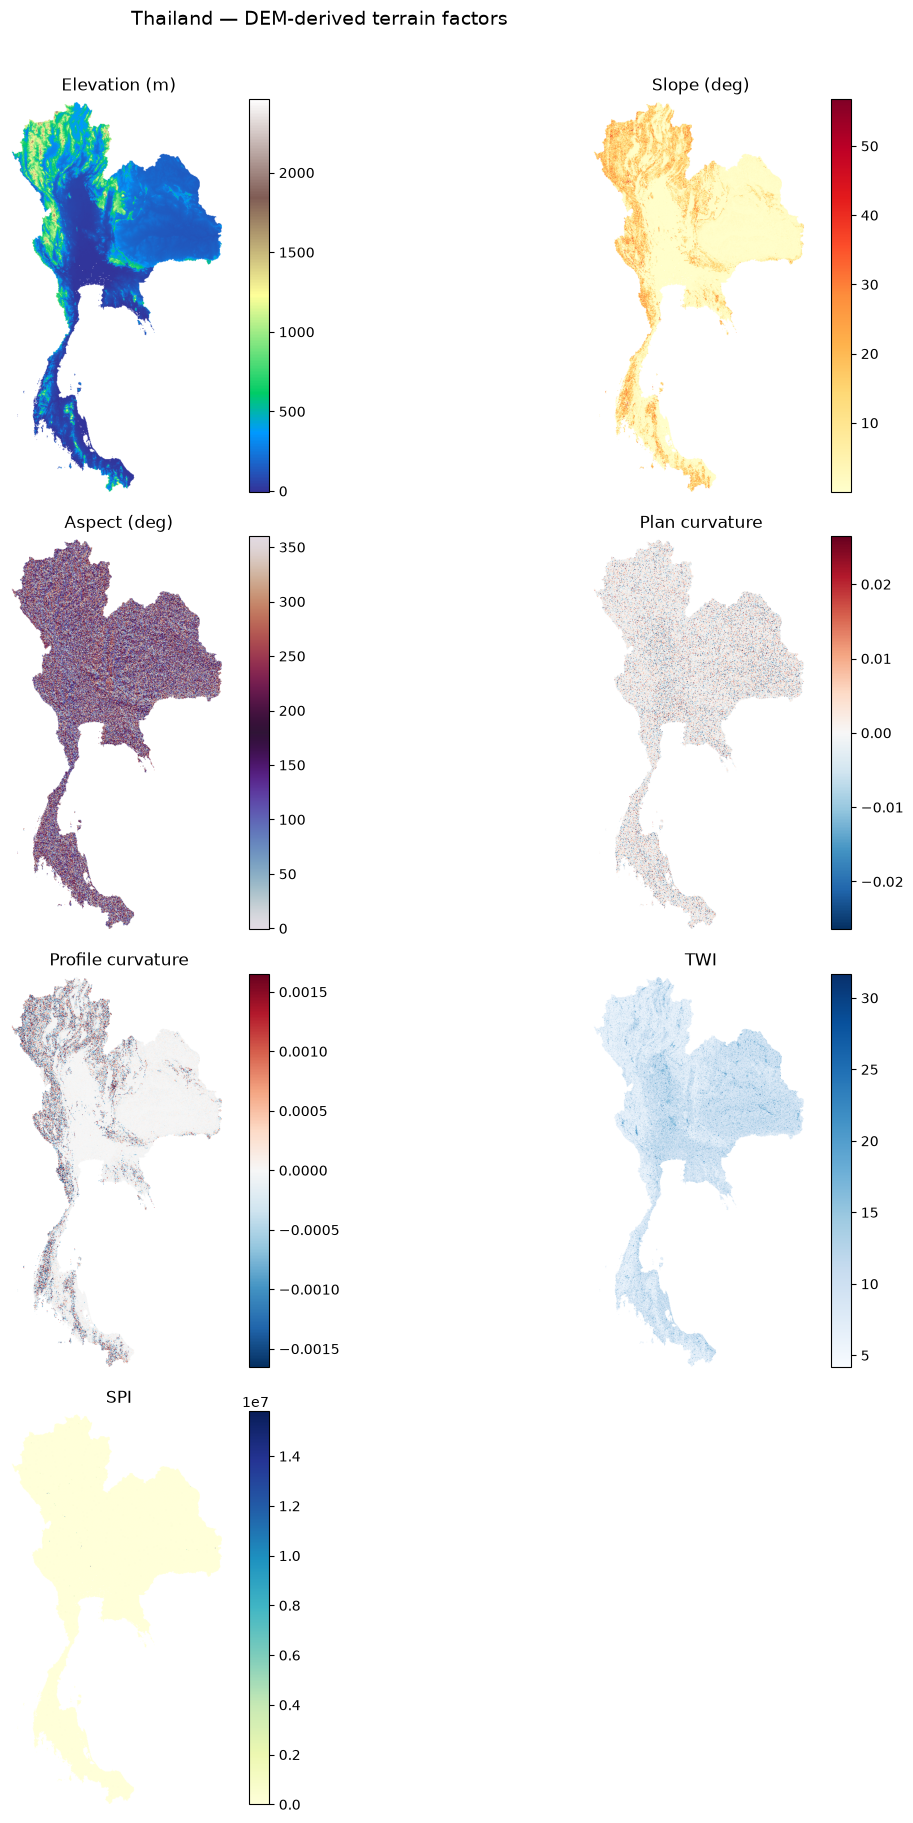

In [22]:
# 9b — Visual QA of DEM-derived terrain factors (memory-safe previews)

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

def load_preview(path, max_dim=800):
    """Downsample a raster on read so large Thailand-wide rasters don't
    have to be fully loaded into memory just to preview them."""
    with rasterio.open(path) as src:
        scale = max(1, max(src.height, src.width) // max_dim)
        out_shape = (max(1, src.height // scale), max(1, src.width // scale))
        return src.read(1, out_shape=out_shape, masked=True)

# (title, raster path, colormap, "diverging" for curvature layers that need
#  a zero-centered color scale)
terrain_display = [
    ("Elevation (m)",       DEM_UTM, "terrain",  None),
    ("Slope (deg)",         SLOPE,   "YlOrRd",   None),
    ("Aspect (deg)",        ASPECT,  "twilight", None),
    ("Plan curvature",      PLANC,   "RdBu_r",   "diverging"),
    ("Profile curvature",   PROFC,   "RdBu_r",   "diverging"),
    ("TWI",                 TWI,     "Blues",    None),
    ("SPI",                 SPI,     "YlGnBu",   None),
]

fig, axes = plt.subplots(4, 2, figsize=(12, 18))
axes = axes.ravel()

for ax, (title, path, cmap, kind) in zip(axes, terrain_display):
    preview = load_preview(path)

    if kind == "diverging":
        vmax = float(np.nanpercentile(np.abs(preview.filled(np.nan)), 98)) or 1.0
        im = ax.imshow(preview, cmap=cmap, norm=TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax))
    else:
        im = ax.imshow(preview, cmap=cmap)

    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[-1].axis("off")  # 7 layers in an 8-panel grid — hide the spare panel
fig.suptitle("Thailand — DEM-derived terrain factors", y=1.01, fontsize=14)
fig.tight_layout()
plt.show()


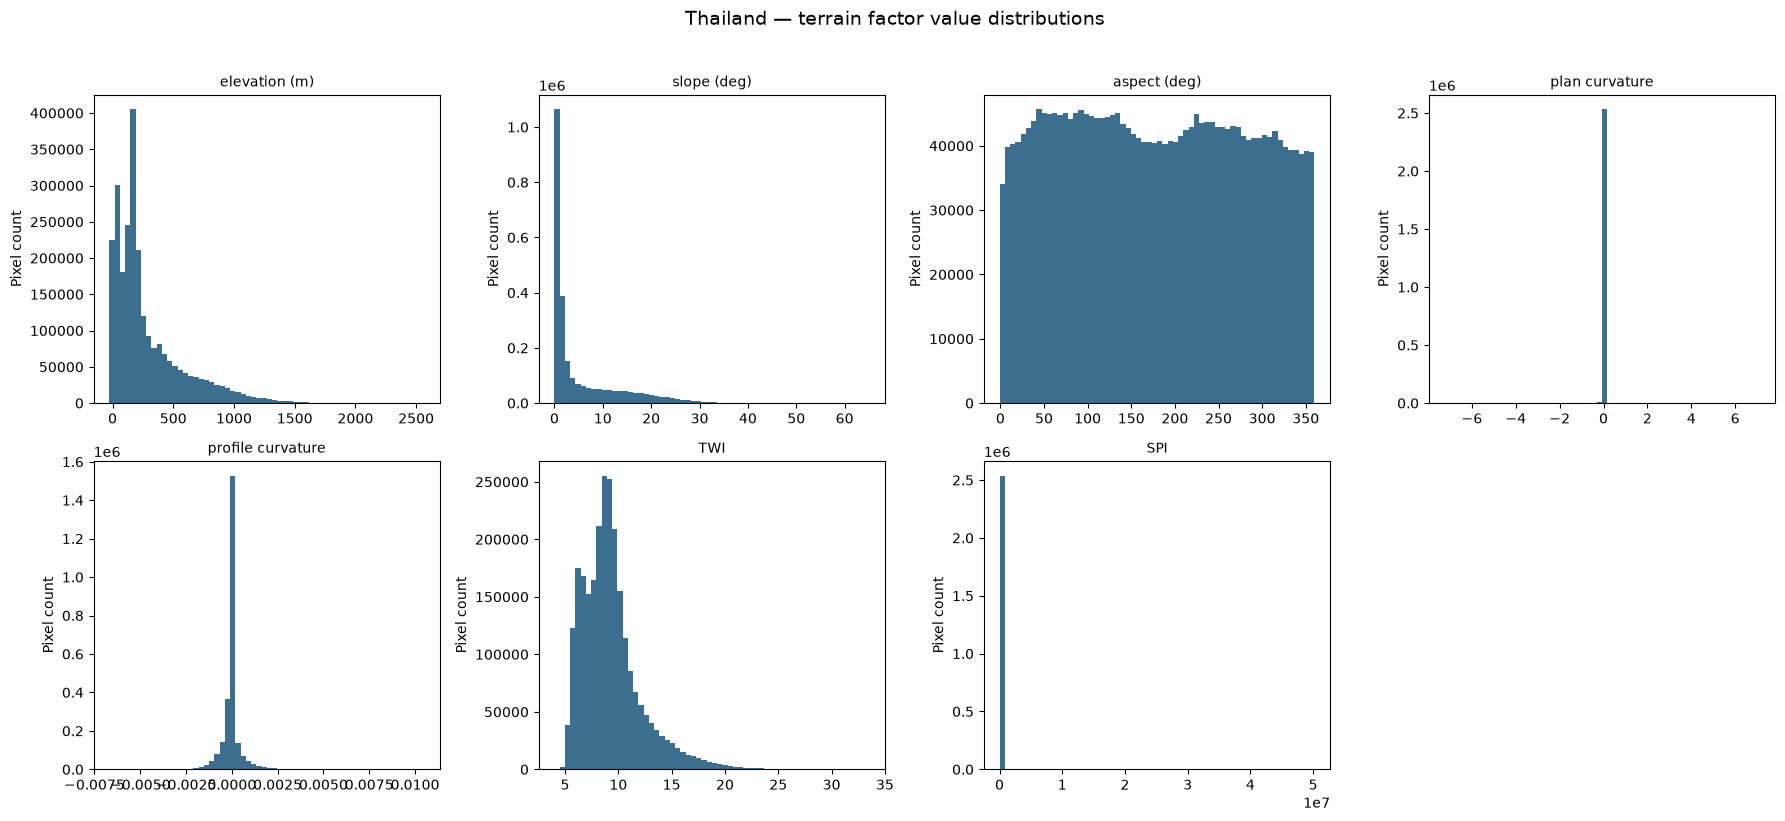

In [23]:
# 9c — Distribution of each terrain factor across the study area

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

for ax, (name, path) in zip(axes, TERRAIN_LAYERS.items()):
    with rasterio.open(path) as src:
        # Sample the full raster in a memory-safe way for the histogram too.
        preview = src.read(
            1,
            out_shape=(max(1, src.height // 5), max(1, src.width // 5)),
            masked=True
        )
    values = preview.compressed()  # drop masked/nodata cells
    ax.hist(values, bins=60, color="#3B6E8F")
    ax.set_title(name, fontsize=10)
    ax.set_ylabel("Pixel count")

for ax in axes[len(TERRAIN_LAYERS):]:
    ax.axis("off")

fig.suptitle("Thailand — terrain factor value distributions", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()


## 6. Add static soil and vegetation/land-cover factors

### 6.1 SoilGrids 2.0

The Thailand builder uses the same four SoilGrids 2.0 layers as the Kerala dataset:

- `clay` — clay content
- `sand` — sand content
- `soc` — soil organic carbon
- `bdod` — bulk density

SoilGrids is approximately **250 m**. These layers are resampled to the common 30 m DEM grid only to make point sampling spatially consistent; the resampling does not create new 30 m soil information.

Official SoilGrids integer rasters use conversion factors:

- clay: divide by 10 → %
- sand: divide by 10 → %
- SOC: divide by 10 → g/kg
- bulk density: divide by 100 → kg/dm³

Recommended folder:

`data/raw/Thailand/soilgrids/`

Expected filenames:

- `soilgrids_clay.tif`
- `soilgrids_sand.tif`
- `soilgrids_soc.tif`
- `soilgrids_bdod.tif`

Set `AUTO_DOWNLOAD_SOILGRIDS = True` to attempt a one-time WCS subset download.

In [27]:
# 10 — Download Thailand SoilGrids layers (native ~250 m)

from pathlib import Path
import requests
import rasterio

SOIL_RAW_DIR.mkdir(parents=True, exist_ok=True)

SOILGRIDS_VARS = {
    "clay": "clay_0-5cm_mean",
    "sand": "sand_0-5cm_mean",
    "soc":  "soc_0-5cm_mean",
    "bdod": "bdod_0-5cm_mean",
}


# ---------------------------------------------------------
# Thailand geographic bounds
# ---------------------------------------------------------

boundary_wgs84 = thailand_boundary.to_crs("EPSG:4326")

minx, miny, maxx, maxy = boundary_wgs84.total_bounds

print("--- SoilGrids download extent ---")
print(f"West : {minx:.4f}")
print(f"South: {miny:.4f}")
print(f"East : {maxx:.4f}")
print(f"North: {maxy:.4f}")


# ---------------------------------------------------------
# Download helper
# ---------------------------------------------------------

def download_soilgrids_layer(
    variable_name,
    coverage_id,
    output_path,
    timeout=900
):
    """
    Download one SoilGrids coverage for the Thailand extent.

    SoilGrids is downloaded at its native resolution.
    It will be aligned/resampled to the Thailand 90 m DEM
    grid in the following processing cell.
    """

    soil_property = coverage_id.split("_")[0]

    url = "https://maps.isric.org/mapserv"

    params = {
        "map": f"/map/{soil_property}.map",
        "SERVICE": "WCS",
        "VERSION": "2.0.1",
        "REQUEST": "GetCoverage",
        "COVERAGEID": coverage_id,
        "FORMAT": "GEOTIFF_INT16",

        # Geographic Thailand bounding box
        "SUBSET": [
            f"X({minx},{maxx})",
            f"Y({miny},{maxy})",
        ],

        "SUBSETTINGCRS": (
            "http://www.opengis.net/def/crs/EPSG/0/4326"
        ),

        "OUTPUTCRS": (
            "http://www.opengis.net/def/crs/EPSG/0/4326"
        ),
    }

    print()
    print(f"Downloading {variable_name}...")
    print("Coverage:", coverage_id)
    print("Output  :", output_path)

    response = requests.get(
        url,
        params=params,
        timeout=timeout,
    )

    if response.status_code != 200:

        raise RuntimeError(
            f"SoilGrids request failed for {variable_name} "
            f"(HTTP {response.status_code}):\n"
            f"{response.text[:1000]}"
        )

    # WCS can sometimes return an XML error document even
    # when the HTTP request itself succeeds.
    content_type = response.headers.get(
        "Content-Type",
        ""
    ).lower()

    if (
        "xml" in content_type
        or response.content[:5].startswith(b"<?xml")
    ):

        raise RuntimeError(
            f"SoilGrids returned an XML error for "
            f"{variable_name}:\n"
            f"{response.text[:1000]}"
        )

    output_path.write_bytes(
        response.content
    )

    if (
        not output_path.exists()
        or output_path.stat().st_size == 0
    ):

        raise RuntimeError(
            f"SoilGrids download for {variable_name} "
            "created an empty file."
        )


    # -----------------------------------------------------
    # Validate downloaded raster
    # -----------------------------------------------------

    try:

        with rasterio.open(
            output_path
        ) as src:

            print(
                "Shape     :",
                src.shape
            )

            print(
                "CRS       :",
                src.crs
            )

            print(
                "Resolution:",
                src.res
            )

            print(
                "Nodata    :",
                src.nodata
            )

            print(
                "File size :",
                f"{output_path.stat().st_size / 1e6:.1f} MB"
            )

    except Exception as exc:

        # Delete invalid download so the notebook can retry
        # correctly next time.
        if output_path.exists():
            output_path.unlink()

        raise RuntimeError(
            f"{variable_name} download is not a valid "
            f"GeoTIFF: {exc}"
        )

    print(
        f"{variable_name}: successfully saved."
    )


# ---------------------------------------------------------
# Download each SoilGrids variable
# ---------------------------------------------------------

for name, layer in SOILGRIDS_VARS.items():

    out_path = (
        SOIL_RAW_DIR
        / f"soilgrids_{name}.tif"
    )

    if out_path.exists():

        # Validate existing file before blindly reusing it.
        try:

            with rasterio.open(
                out_path
            ) as src:

                print(
                    f"{name}: already available "
                    f"(shape={src.shape}, CRS={src.crs})"
                )

            continue

        except Exception:

            print(
                f"{name}: existing file is invalid; "
                "deleting and downloading again."
            )

            out_path.unlink()


    if not AUTO_DOWNLOAD_SOILGRIDS:

        print(
            f"{name}: missing "
            "(automatic download disabled)"
        )

        continue


    download_soilgrids_layer(
        name,
        layer,
        out_path
    )


print(
    "\nSoilGrids download step completed."
)

--- SoilGrids download extent ---
West : 97.3438
South: 5.6129
East : 105.6368
North: 20.4648

Coverage: clay_0-5cm_mean
Output  : D:\PROJECTS\Landslide_prediction\data\raw\Thailand\soilgrids\soilgrids_clay.tif
Shape     : (6214, 3668)
CRS       : EPSG:4326
Resolution: (0.002260906434023991, 0.002390080865786933)
Nodata    : None
File size : 13.4 MB
clay: successfully saved.

Coverage: sand_0-5cm_mean
Output  : D:\PROJECTS\Landslide_prediction\data\raw\Thailand\soilgrids\soilgrids_sand.tif
Shape     : (6214, 3668)
CRS       : EPSG:4326
Resolution: (0.002260906434023991, 0.002390080865786933)
Nodata    : None
File size : 13.2 MB
sand: successfully saved.

Coverage: soc_0-5cm_mean
Output  : D:\PROJECTS\Landslide_prediction\data\raw\Thailand\soilgrids\soilgrids_soc.tif
Shape     : (6214, 3668)
CRS       : EPSG:4326
Resolution: (0.002260906434023991, 0.002390080865786933)
Nodata    : None
File size : 16.6 MB
soc: successfully saved.

Coverage: bdod_0-5cm_mean
Output  : D:\PROJECTS\Landslid

In [28]:
# Check SoilGrids rasters

SOIL_PATHS = {
    "clay": SOIL_RAW_DIR / "soilgrids_clay.tif",
    "sand": SOIL_RAW_DIR / "soilgrids_sand.tif",
    "soc": SOIL_RAW_DIR / "soilgrids_soc.tif",
    "bdod": SOIL_RAW_DIR / "soilgrids_bdod.tif",
}

for name, path in SOIL_PATHS.items():
    if path.exists():
        print(f"{name:5s} | exists=True | size={path.stat().st_size / 1024 / 1024:.2f} MB")
    else:
        print(f"{name:5s} | NOT FOUND")

clay  | exists=True | size=12.79 MB
sand  | exists=True | size=12.55 MB
soc   | exists=True | size=15.88 MB
bdod  | exists=True | size=7.79 MB


In [29]:
# Inspect available SoilGrids rasters

for name, path in SOIL_PATHS.items():
    if not path.exists():
        continue

    with rasterio.open(path) as src:
        print()
        print(name.upper())
        print("CRS:", src.crs)
        print("Shape:", src.shape)
        print("Bounds:", src.bounds)
        print("NoData:", src.nodata)
        print("Data type:", src.dtypes[0])



CLAY
CRS: EPSG:4326
Shape: (6214, 3668)
Bounds: BoundingBox(left=97.3438072, bottom=5.612851000000003, right=105.63681199999999, top=20.464813500000005)
NoData: None
Data type: int16

SAND
CRS: EPSG:4326
Shape: (6214, 3668)
Bounds: BoundingBox(left=97.3438072, bottom=5.612851000000003, right=105.63681199999999, top=20.464813500000005)
NoData: None
Data type: int16

SOC
CRS: EPSG:4326
Shape: (6214, 3668)
Bounds: BoundingBox(left=97.3438072, bottom=5.612851000000003, right=105.63681199999999, top=20.464813500000005)
NoData: None
Data type: int16

BDOD
CRS: EPSG:4326
Shape: (6214, 3668)
Bounds: BoundingBox(left=97.3438072, bottom=5.612851000000003, right=105.63681199999999, top=20.464813500000005)
NoData: None
Data type: int16


In [30]:
#Align them to your Thailand DEM
from rasterio.warp import reproject, Resampling
import numpy as np


def prepare_continuous_factor(
    src_path,
    out_path,
    reference_path
):
    """
    Reproject/resample a continuous raster
    to exactly match the Thailand DEM grid.
    """

    with rasterio.open(reference_path) as ref:

        ref_profile = ref.profile.copy()
        ref_crs = ref.crs
        ref_transform = ref.transform
        ref_height = ref.height
        ref_width = ref.width

    with rasterio.open(src_path) as src:

        destination = np.full(
            (ref_height, ref_width),
            np.nan,
            dtype="float32"
        )

        reproject(
            source=rasterio.band(src, 1),
            destination=destination,

            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,

            dst_transform=ref_transform,
            dst_crs=ref_crs,
            dst_nodata=np.nan,

            resampling=Resampling.bilinear
        )

    ref_profile.update(
        dtype="float32",
        count=1,
        nodata=np.nan,
        compress="deflate"
    )

    with rasterio.open(
        out_path,
        "w",
        **ref_profile
    ) as dst:

        dst.write(destination, 1)

    return out_path

In [31]:
# Align SoilGrids rasters to the Thailand DEM grid

required_soil = ["clay", "sand", "soc", "bdod"]
missing_soil = [name for name in required_soil if not SOIL_PATHS[name].exists()]

if missing_soil:
    raise FileNotFoundError(
        "Missing SoilGrids rasters: " + ", ".join(missing_soil) +
        ". Add them to data/raw/Thailand/soilgrids/ or enable AUTO_DOWNLOAD_SOILGRIDS."
    )

CLAY = prepare_continuous_factor(
    SOIL_PATHS["clay"],
    FACTOR_DIR / "map_clay.tif",
    DEM_UTM
)
SAND = prepare_continuous_factor(
    SOIL_PATHS["sand"],
    FACTOR_DIR / "map_sand.tif",
    DEM_UTM
)
SOC = prepare_continuous_factor(
    SOIL_PATHS["soc"],
    FACTOR_DIR / "map_soc.tif",
    DEM_UTM
)
BDOD = prepare_continuous_factor(
    SOIL_PATHS["bdod"],
    FACTOR_DIR / "map_bdod.tif",
    DEM_UTM
)

print("Soil factors aligned with the Thailand DEM grid.")

Soil factors aligned with the Thailand DEM grid.


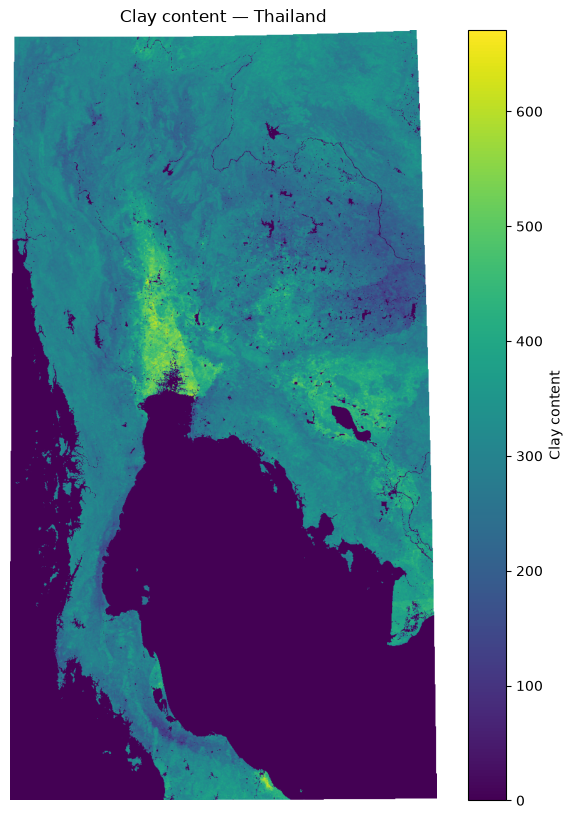

Clay content: min=0.00, max=670.50


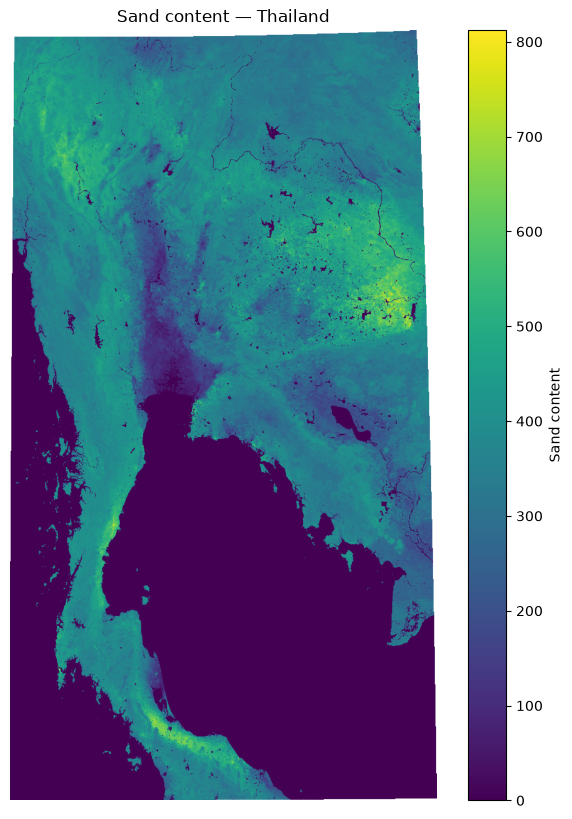

Sand content: min=0.00, max=812.04


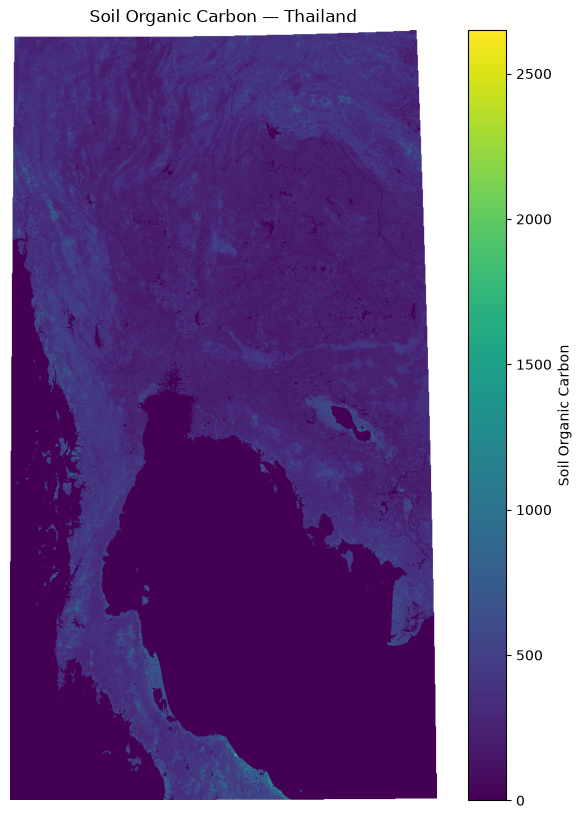

Soil Organic Carbon: min=0.00, max=2648.86


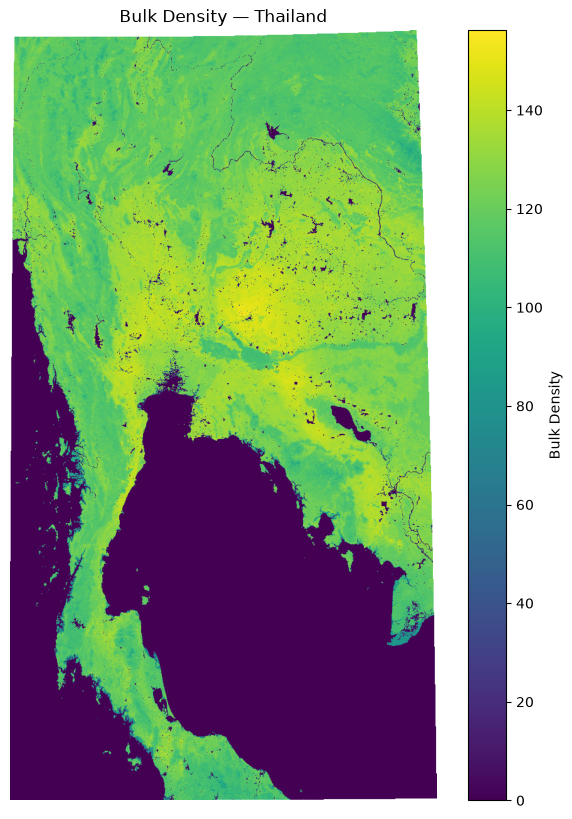

Bulk Density: min=0.00, max=156.17


In [32]:
# Visualize SoilGrids factors safely without loading full rasters

import rasterio
import matplotlib.pyplot as plt
import numpy as np

soil_rasters = {
    "Clay content": CLAY,
    "Sand content": SAND,
    "Soil Organic Carbon": SOC,
    "Bulk Density": BDOD,
}

for title, raster_path in soil_rasters.items():

    with rasterio.open(raster_path) as src:

        # Downsample for visualization only
        preview = src.read(
            1,
            out_shape=(
                src.height // 15,
                src.width // 15
            ),
            masked=True
        )

    plt.figure(figsize=(8, 10))

    plt.imshow(preview)

    plt.title(f"{title} — Thailand")
    plt.colorbar(label=title)

    plt.axis("off")
    plt.show()

    print(
        f"{title}: "
        f"min={preview.min():.2f}, "
        f"max={preview.max():.2f}"
    )

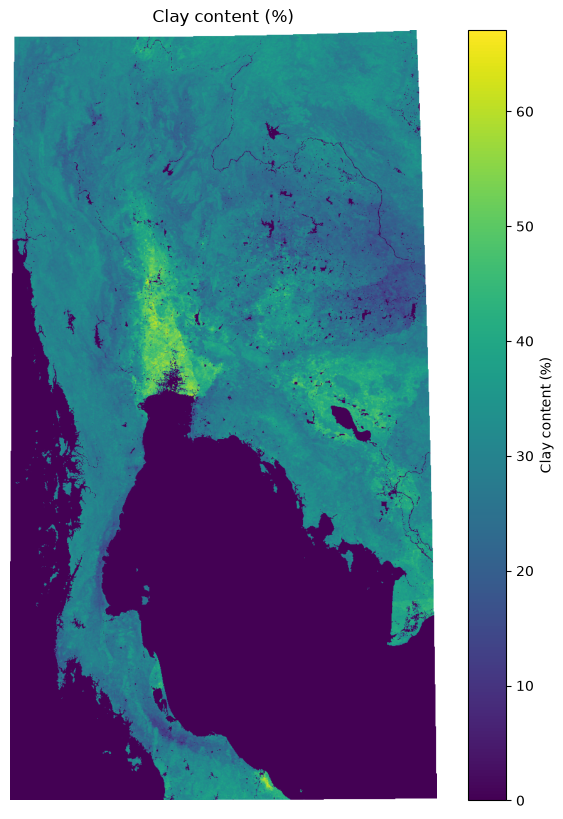

Clay content (%)
Min: 0.0
Max: 67.05
Mean: 18.54



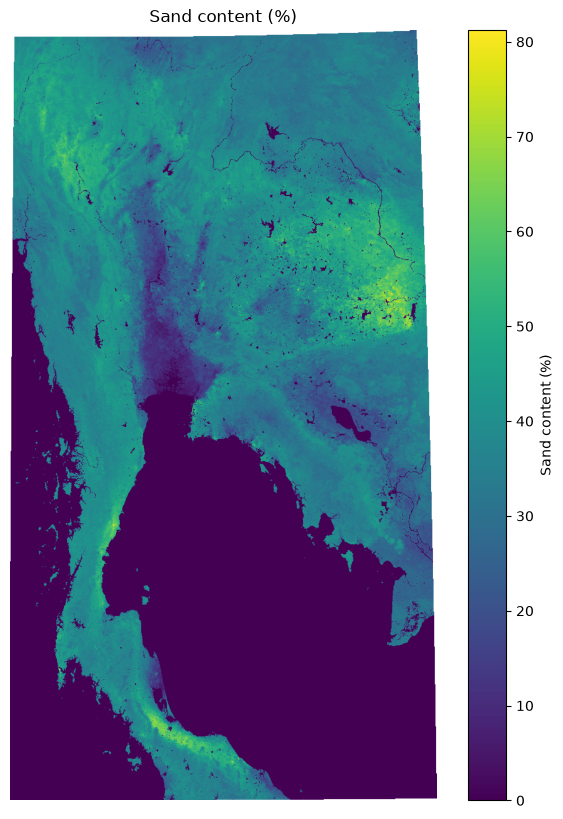

Sand content (%)
Min: 0.0
Max: 81.2
Mean: 22.42



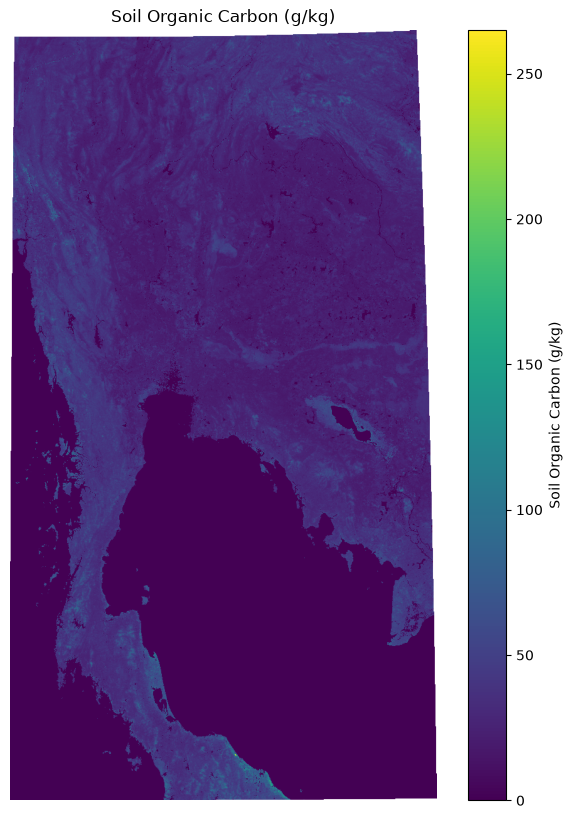

Soil Organic Carbon (g/kg)
Min: 0.0
Max: 264.89
Mean: 19.83



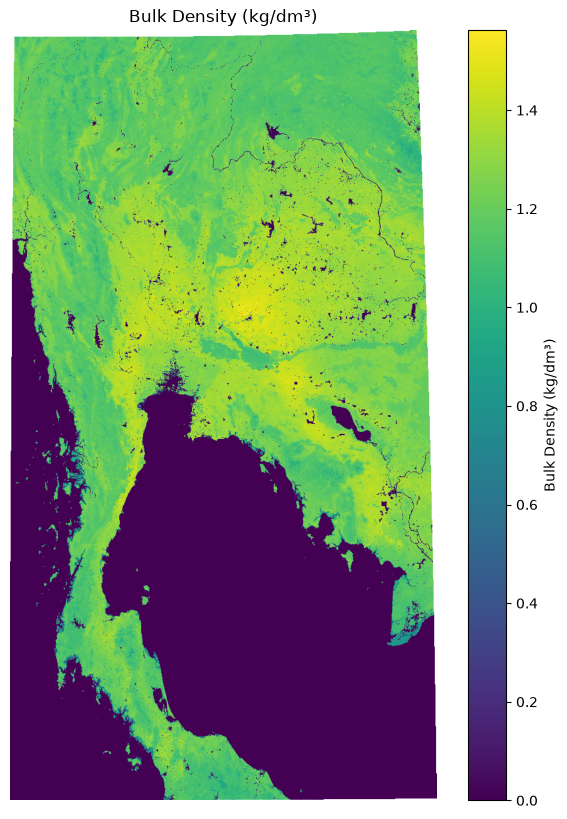

Bulk Density (kg/dm³)
Min: 0.0
Max: 1.56
Mean: 0.75



In [33]:
# Soil factor visualization with interpretable units

soil_rasters = {
    "Clay content (%)": {
        "path": CLAY,
        "divisor": 10.0
    },

    "Sand content (%)": {
        "path": SAND,
        "divisor": 10.0
    },

    "Soil Organic Carbon (g/kg)": {
        "path": SOC,
        "divisor": 10.0
    },

    "Bulk Density (kg/dm³)": {
        "path": BDOD,
        "divisor": 100.0
    },
}


for title, info in soil_rasters.items():

    with rasterio.open(info["path"]) as src:

        preview = src.read(
            1,
            out_shape=(
                src.height // 15,
                src.width // 15
            ),
            masked=True
        ).astype("float32")

    # Convert only the visualization copy
    preview = preview / info["divisor"]


    plt.figure(figsize=(8, 10))

    plt.imshow(preview)

    plt.title(title)

    plt.colorbar(
        label=title
    )

    plt.axis("off")

    plt.show()


    print(
        title
    )

    print(
        "Min:",
        round(float(preview.min()), 2)
    )

    print(
        "Max:",
        round(float(preview.max()), 2)
    )

    print(
        "Mean:",
        round(float(preview.mean()), 2)
    )

    print()

### 6.2 ESA WorldCover 2021 vegetation/land-cover

ESA WorldCover 2021 is a **10 m categorical** land-cover product. Thailand intersects many 3° × 3° WorldCover tiles, so this notebook **does not assume a single tile**. It computes the required tile IDs from the Thailand boundary and processes each available tile directly onto the common 30 m DEM grid using nearest-neighbour resampling.

For a nationwide Thailand run, the WorldCover download can be large. For reproducibility, the recommended approach is to download the required tiles once into:

`data/raw/Thailand/worldcover_2021/`

Set `AUTO_DOWNLOAD_WORLDCOVER = True` only when you intentionally want the notebook to download missing tiles.

In [34]:
# 11 — Compute all ESA WorldCover tiles intersecting Thailand

import math

boundary_wgs84 = thailand_boundary.to_crs("EPSG:4326")
minx, miny, maxx, maxy = boundary_wgs84.total_bounds

print("Thailand bounds:")
print("Longitude:", minx, "to", maxx)
print("Latitude :", miny, "to", maxy)


def worldcover_tile_name(lat, lon):
    lat_base = math.floor(lat / 3) * 3
    lon_base = math.floor(lon / 3) * 3

    lat_prefix = "N" if lat_base >= 0 else "S"
    lon_prefix = "E" if lon_base >= 0 else "W"

    return (
        f"{lat_prefix}{abs(lat_base):02d}"
        f"{lon_prefix}{abs(lon_base):03d}"
    )


tiles = []
lat = math.floor(miny / 3) * 3

while lat <= maxy:
    lon = math.floor(minx / 3) * 3

    while lon <= maxx:
        tiles.append(worldcover_tile_name(lat + 0.01, lon + 0.01))
        lon += 3

    lat += 3

tiles = sorted(set(tiles))

print()
print("Potential WorldCover tiles:")
for tile in tiles:
    print(tile)
print("Total potential tiles:", len(tiles))


Thailand bounds:
Longitude: 97.3438072 to 105.636812
Latitude : 5.612851 to 20.4648135

Potential WorldCover tiles:
N03E096
N03E099
N03E102
N03E105
N06E096
N06E099
N06E102
N06E105
N09E096
N09E099
N09E102
N09E105
N12E096
N12E099
N12E102
N12E105
N15E096
N15E099
N15E102
N15E105
N18E096
N18E099
N18E102
N18E105
Total potential tiles: 24


In [35]:
# The tile list above is based on the Thailand bounding box.
# Tiles that are entirely ocean or unavailable will simply be skipped during download/discovery.
print("WorldCover tile discovery ready.")

WorldCover tile discovery ready.


In [36]:
# 12 — Discover/download WorldCover tiles

WORLDCOVER_RAW_DIR.mkdir(parents=True, exist_ok=True)
downloaded_tiles = []
missing_tiles = []

for tile in tiles:
    filename = f"ESA_WorldCover_10m_2021_v200_{tile}_Map.tif"
    out_path = WORLDCOVER_RAW_DIR / filename

    if out_path.exists():
        downloaded_tiles.append(out_path)
        print(tile, "available")
        continue

    if not AUTO_DOWNLOAD_WORLDCOVER:
        missing_tiles.append(tile)
        continue

    url = (
        "https://esa-worldcover.s3.eu-central-1.amazonaws.com/"
        f"v200/2021/map/{filename}"
    )

    print("Downloading:", tile)
    response = requests.get(url, timeout=600)

    if response.status_code == 200:
        out_path.write_bytes(response.content)
        downloaded_tiles.append(out_path)
        print("  saved")
    else:
        missing_tiles.append(tile)
        print("  unavailable:", response.status_code)

print()
print("Available WorldCover tiles:", len(downloaded_tiles))
print("Missing/unavailable tiles   :", len(missing_tiles))

if missing_tiles and not AUTO_DOWNLOAD_WORLDCOVER:
    print("Automatic download is disabled. Add the missing required tiles to:", WORLDCOVER_RAW_DIR)


Downloading: N03E096
  saved
Downloading: N03E099
  saved
Downloading: N03E102
  saved
Downloading: N03E105
  saved
Downloading: N06E096
  saved
Downloading: N06E099
  saved
Downloading: N06E102
  saved
Downloading: N06E105
  saved
Downloading: N09E096
  saved
Downloading: N09E099
  saved
Downloading: N09E102
  saved
Downloading: N09E105
  saved
Downloading: N12E096
  saved
Downloading: N12E099
  saved
Downloading: N12E102
  saved
Downloading: N12E105
  saved
Downloading: N15E096
  saved
Downloading: N15E099
  saved
Downloading: N15E102
  saved
Downloading: N15E105
  saved
Downloading: N18E096
  saved
Downloading: N18E099
  saved
Downloading: N18E102
  saved
Downloading: N18E105
  saved

Available WorldCover tiles: 24
Missing/unavailable tiles   : 0


In [37]:
# Prepare ESA WorldCover directly on the 90 m Thailand DEM grid
# No nationwide 10 m mosaic is created.

LANDCOVER = FACTOR_DIR / "map_landcover.tif"

if not downloaded_tiles:
    LANDCOVER = None
    print("WorldCover factor skipped because no source tiles are available.")
else:
    with rasterio.open(DEM_UTM) as ref:
        profile = ref.profile.copy()
        profile.update(
            dtype="uint8",
            count=1,
            nodata=0,
            compress="deflate"
        )
        ref_crs = ref.crs
        ref_transform = ref.transform

    with rasterio.open(LANDCOVER, "w+", **profile) as dst:
        for tile_path in downloaded_tiles:
            print("Processing:", tile_path.name)

            with rasterio.open(tile_path) as src:
                reproject(
                    source=rasterio.band(src, 1),
                    destination=rasterio.band(dst, 1),
                    src_transform=src.transform,
                    src_crs=src.crs,
                    src_nodata=src.nodata,
                    dst_transform=ref_transform,
                    dst_crs=ref_crs,
                    dst_nodata=0,
                    resampling=Resampling.nearest,
                    init_dest_nodata=False
                )

    print()
    print("Thailand WorldCover prepared:")
    print(LANDCOVER)


Processing: ESA_WorldCover_10m_2021_v200_N03E096_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N03E099_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N03E102_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N03E105_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N06E096_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N06E099_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N06E102_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N06E105_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N09E096_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N09E099_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N09E102_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N09E105_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N12E096_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N12E099_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N12E102_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N12E105_Map.tif
Processing: ESA_WorldCover_10m_2021_v200_N15E096_Map.tif
Processing: ESA_WorldCover_10m_

In [38]:
# Verify WorldCover alignment when available

if LANDCOVER is not None and Path(LANDCOVER).exists():
    with rasterio.open(DEM_UTM) as dem, rasterio.open(LANDCOVER) as lc:
        print("Same CRS      :", dem.crs == lc.crs)
        print("Same shape    :", dem.shape == lc.shape)
        print("Same transform:", dem.transform == lc.transform)
else:
    print("WorldCover alignment check skipped.")

Same CRS      : True
Same shape    : True
Same transform: True


Preview shape: (1227, 680)


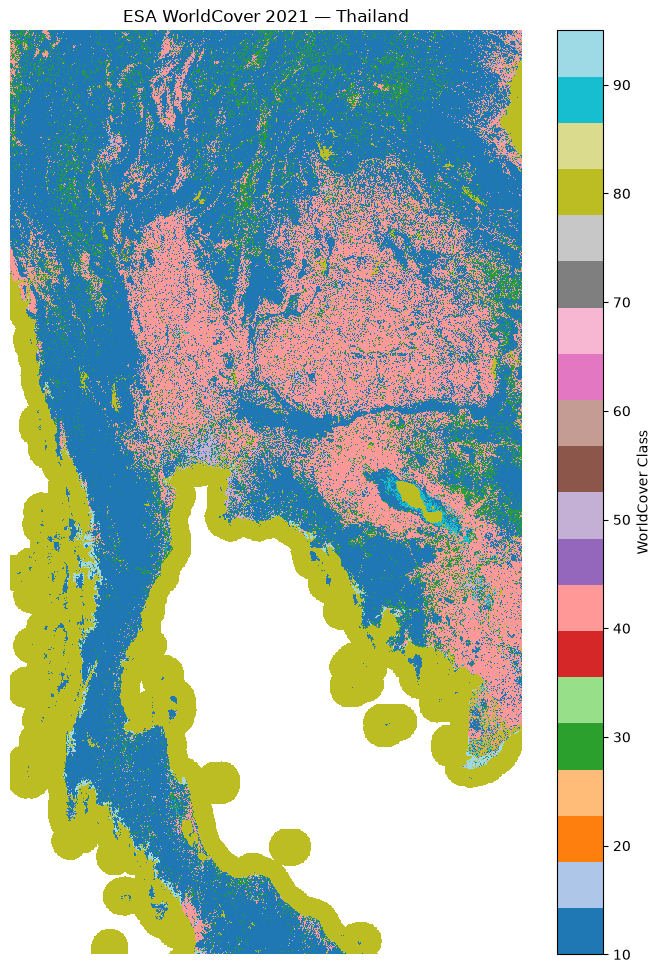

In [39]:
# Memory-safe visualization of Thailand WorldCover

if LANDCOVER is not None and Path(LANDCOVER).exists():
    with rasterio.open(LANDCOVER) as src:
        preview_height = max(1, src.height // 15)
        preview_width = max(1, src.width // 15)
        landcover_preview = src.read(
            1,
            out_shape=(preview_height, preview_width),
            masked=True
        )

    print("Preview shape:", landcover_preview.shape)

    plt.figure(figsize=(9, 12))
    plt.imshow(landcover_preview, cmap="tab20", interpolation="nearest")
    plt.title("ESA WorldCover 2021 — Thailand")
    plt.colorbar(label="WorldCover Class")
    plt.axis("off")
    plt.show()
else:
    print("WorldCover visualization skipped.")

WorldCover tiles found: 24
Displayed 01/24: ESA_WorldCover_10m_2021_v200_N03E096_Map.tif
Displayed 02/24: ESA_WorldCover_10m_2021_v200_N03E099_Map.tif
Displayed 03/24: ESA_WorldCover_10m_2021_v200_N03E102_Map.tif
Displayed 04/24: ESA_WorldCover_10m_2021_v200_N03E105_Map.tif
Displayed 05/24: ESA_WorldCover_10m_2021_v200_N06E096_Map.tif
Displayed 06/24: ESA_WorldCover_10m_2021_v200_N06E099_Map.tif
Displayed 07/24: ESA_WorldCover_10m_2021_v200_N06E102_Map.tif
Displayed 08/24: ESA_WorldCover_10m_2021_v200_N06E105_Map.tif
Displayed 09/24: ESA_WorldCover_10m_2021_v200_N09E096_Map.tif
Displayed 10/24: ESA_WorldCover_10m_2021_v200_N09E099_Map.tif
Displayed 11/24: ESA_WorldCover_10m_2021_v200_N09E102_Map.tif
Displayed 12/24: ESA_WorldCover_10m_2021_v200_N09E105_Map.tif
Displayed 13/24: ESA_WorldCover_10m_2021_v200_N12E096_Map.tif
Displayed 14/24: ESA_WorldCover_10m_2021_v200_N12E099_Map.tif
Displayed 15/24: ESA_WorldCover_10m_2021_v200_N12E102_Map.tif
Displayed 16/24: ESA_WorldCover_10m_2021_v2

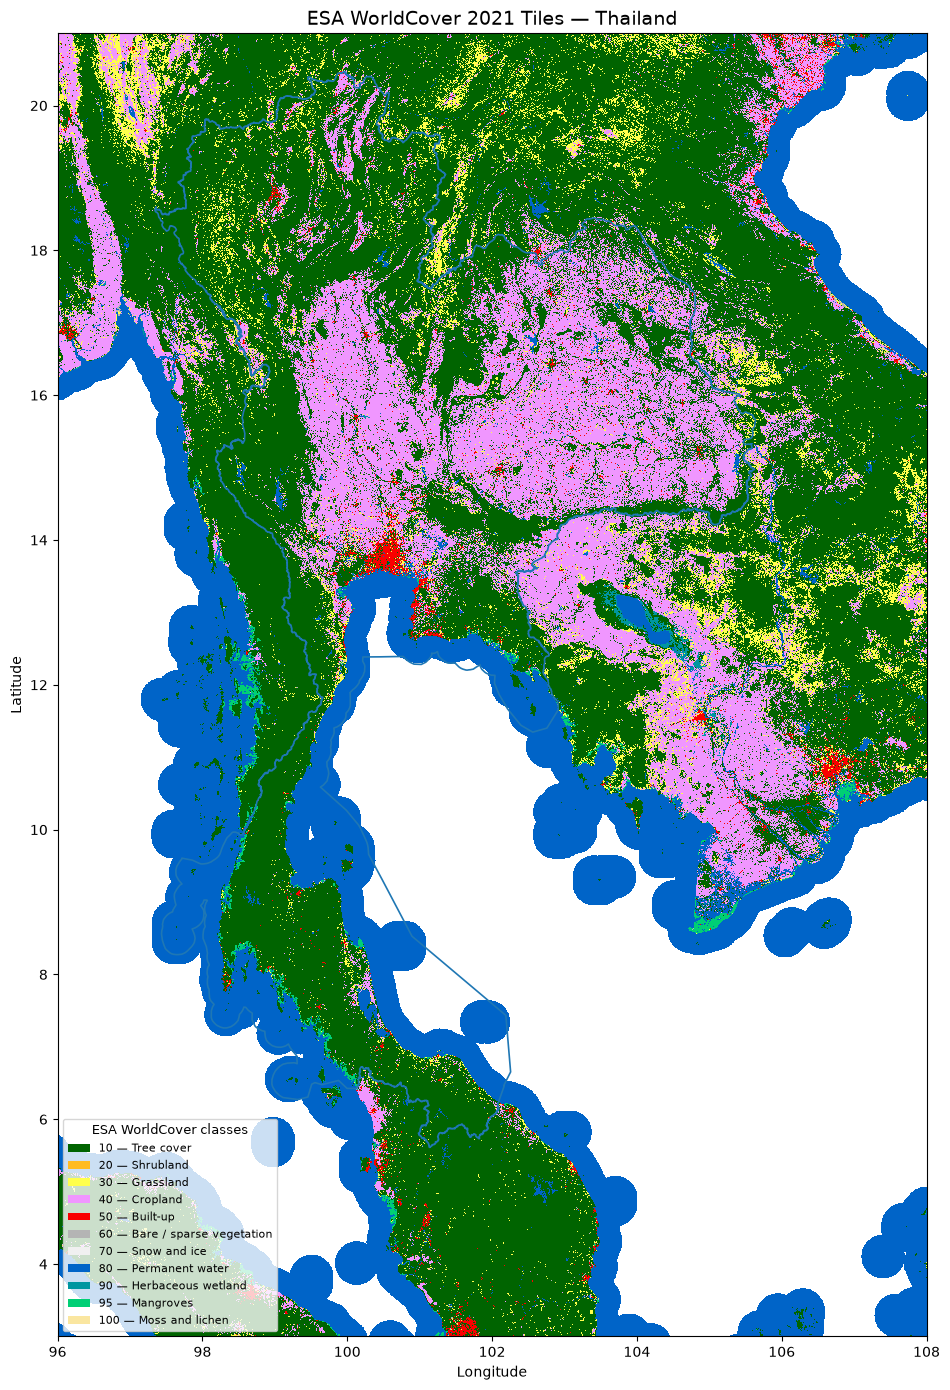

In [44]:
# Visualize downloaded ESA WorldCover tiles over Thailand

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio

from rasterio.enums import Resampling
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# ---------------------------------------------------------
# Find downloaded WorldCover tiles
# ---------------------------------------------------------

# Use the same folder variable from your WorldCover download cell.
# If your variable has another name, change this line only.
worldcover_tiles = sorted(
    WORLDCOVER_RAW_DIR.glob("*.tif")
)

print("WorldCover tiles found:", len(worldcover_tiles))

if not worldcover_tiles:
    raise FileNotFoundError(
        f"No WorldCover .tif files found in {WORLD_COVER_RAW_DIR}"
    )


# ---------------------------------------------------------
# ESA WorldCover class information
# ---------------------------------------------------------

# WorldCover 2021 classes
class_values = [
    10,
    20,
    30,
    40,
    50,
    60,
    70,
    80,
    90,
    95,
    100,
]

class_names = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare / sparse vegetation",
    70: "Snow and ice",
    80: "Permanent water",
    90: "Herbaceous wetland",
    95: "Mangroves",
    100: "Moss and lichen",
}


# Colours only for visualization
class_colors = [
    "#006400",   # Tree cover
    "#ffbb22",   # Shrubland
    "#ffff4c",   # Grassland
    "#f096ff",   # Cropland
    "#fa0000",   # Built-up
    "#b4b4b4",   # Bare
    "#f0f0f0",   # Snow
    "#0064c8",   # Water
    "#0096a0",   # Wetland
    "#00cf75",   # Mangrove
    "#fae6a0",   # Moss
]

cmap = ListedColormap(class_colors)


# ---------------------------------------------------------
# Convert original WorldCover classes to plotting indices
#
# 10 -> 0
# 20 -> 1
# ...
#
# This makes categorical colours display correctly.
# ---------------------------------------------------------

class_to_index = {
    value: i
    for i, value in enumerate(class_values)
}


def convert_for_plot(data):
    """
    Convert WorldCover class codes into sequential plotting indices.
    Unknown / nodata pixels become NaN.
    """

    result = np.full(
        data.shape,
        np.nan,
        dtype="float32"
    )

    for value, index in class_to_index.items():

        result[data == value] = index

    return result


# ---------------------------------------------------------
# Create map
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 14)
)


# Downsampling factor.
#
# WorldCover is ~10 m, so loading the full Thailand dataset
# just for visualization would use a lot of RAM.
#
# factor=30 means approximately 300 m display pixels.
preview_factor = 30


for i, tile_path in enumerate(worldcover_tiles, start=1):

    with rasterio.open(tile_path) as src:

        preview_height = max(
            1,
            src.height // preview_factor
        )

        preview_width = max(
            1,
            src.width // preview_factor
        )

        data = src.read(
            1,
            out_shape=(
                preview_height,
                preview_width
            ),
            resampling=Resampling.nearest
        )

        plot_data = convert_for_plot(data)

        bounds = src.bounds

        ax.imshow(
            plot_data,
            extent=[
                bounds.left,
                bounds.right,
                bounds.bottom,
                bounds.top
            ],
            origin="upper",
            cmap=cmap,
            vmin=0,
            vmax=len(class_values) - 1,
            interpolation="nearest"
        )

    print(
        f"Displayed {i:02d}/{len(worldcover_tiles)}: "
        f"{tile_path.name}"
    )


# ---------------------------------------------------------
# Add Thailand boundary
# ---------------------------------------------------------

# WorldCover tiles normally use EPSG:4326.
# Reproject Thailand boundary to the CRS of the first tile.

with rasterio.open(worldcover_tiles[0]) as src:
    worldcover_crs = src.crs

thailand_wc = thailand_boundary.to_crs(
    worldcover_crs
)

thailand_wc.boundary.plot(
    ax=ax,
    linewidth=1.2
)


# ---------------------------------------------------------
# Legend
# ---------------------------------------------------------

legend_items = [

    Patch(
        facecolor=class_colors[i],
        label=f"{value} — {class_names[value]}"
    )

    for i, value in enumerate(class_values)
]


ax.legend(
    handles=legend_items,
    title="ESA WorldCover classes",
    loc="lower left",
    fontsize=8,
    title_fontsize=9,
    frameon=True
)


# ---------------------------------------------------------
# Map formatting
# ---------------------------------------------------------

ax.set_title(
    "ESA WorldCover 2021 Tiles — Thailand",
    fontsize=14
)

ax.set_xlabel(
    "Longitude"
)

ax.set_ylabel(
    "Latitude"
)

ax.set_aspect(
    "equal"
)

plt.tight_layout()

plt.show()

### Optional NDVI note

NDVI can be a strong continuous vegetation-density indicator, but a **single Sentinel-2 scene is not sufficient for nationwide Thailand**. A defensible nationwide NDVI factor should be built from multiple cloud-masked scenes using a consistent season/date window and mosaicked before this notebook samples it.

If you later create a nationwide NDVI GeoTIFF, set:

```python
NDVI_RAW_PATH = RAW_DIR / "thailand_ndvi.tif"
```

in the configuration cell and rerun the static-factor preparation/sampling cells.


In [45]:
# 13 — Save ESA WorldCover class legend for reproducibility

WORLDCOVER_LEGEND = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare / sparse vegetation",
    70: "Snow and ice",
    80: "Permanent water bodies",
    90: "Herbaceous wetland",
    95: "Mangroves",
    100: "Moss and lichen",
}

legend_df = pd.DataFrame(
    [{"landcover": k, "class_name": v} for k, v in WORLDCOVER_LEGEND.items()]
)
legend_path = PROCESSED_DIR / "worldcover_2021_class_legend.csv"
legend_df.to_csv(legend_path, index=False)

print("Saved WorldCover legend:", legend_path)
legend_df


Saved WorldCover legend: D:\PROJECTS\Landslide_prediction\data\processed\worldcover_2021_class_legend.csv


,landcover,class_name
0,10,Tree cover
1,20,Shrubland
2,30,Grassland
3,40,Cropland
4,50,Built-up
5,60,Bare / sparse vegetation
6,70,Snow and ice
7,80,Permanent water bodies
8,90,Herbaceous wetland
9,95,Mangroves


## 7. Distance-to-river / distance-to-road

`distriv` and `distroad` are **excluded from this Thailand version**. Multiple live Overpass approaches were tested but were not reliable enough for a reproducible national-scale research pipeline. This limitation is recorded in the manifest.

They should only be added later from a stable local vector source (for example, a locally downloaded OSM extract or an authoritative Thailand hydrography/road dataset).


In [46]:
# 14 — Record skipped OSM factors

DISTRIV_AVAILABLE = False
DISTROAD_AVAILABLE = False

print("distriv/distroad skipped in this reproducible version.")


distriv/distroad skipped in this reproducible version.


## 8. Generate balanced pseudo-absence points

The complete DMR event inventory remains preserved. The main susceptibility model uses **one row per unique landslide location**.

Repeated-coordinate information is retained through `landslide_count`, `recurrence_proxy_flag`, `recurrence_class`, and `recurrence_weight`.

Pseudo-absence points are sampled:

- inside the Thailand national boundary,
- at least `EXCLUSION_BUFFER_M` (default 1,000 m) from **every known unique landslide location**,
- only where the common DEM has a valid value,
- with the same number of pseudo-absences as selected positive locations,
- using a fixed random seed for reproducibility.

If `MAX_POSITIVES` is used for an experiment, the exclusion buffer still uses **all known unique landslide locations**, preventing omitted positive locations from becoming false pseudo-absences.


In [47]:
# 15 — Prepare recurrence-aware unique landslide points for susceptibility modelling

# The unique-location table was created from the full event inventory above.
all_unique_landslides_utm = unique_landslide_locations.to_crs(TARGET_CRS).copy()

source_count = len(event_inventory)
unique_location_count = len(all_unique_landslides_utm)
duplicate_location_rows = source_count - unique_location_count

landslides_utm = all_unique_landslides_utm.copy()

if MAX_POSITIVES is not None and len(landslides_utm) > MAX_POSITIVES:
    landslides_utm = landslides_utm.sample(
        n=MAX_POSITIVES,
        random_state=RANDOM_STATE
    ).reset_index(drop=True)
else:
    landslides_utm = landslides_utm.reset_index(drop=True)

landslides_utm["lslpts"] = "TRUE"
landslides_utm["label"] = 1
landslides_utm["source"] = "Thailand_DMR_Landslide_Inventory"

country_utm = thailand_boundary.to_crs(TARGET_CRS)
country_geom_utm = country_utm.geometry.union_all()

# IMPORTANT:
# Buffer ALL known unique landslide locations, even if MAX_POSITIVES
# reduces the positive modelling sample.
exclusion_geom = (
    all_unique_landslides_utm.geometry
    .buffer(EXCLUSION_BUFFER_M)
    .union_all()
)

allowed_geom = country_geom_utm.difference(exclusion_geom)

if allowed_geom.is_empty:
    raise ValueError("Pseudo-absence sampling area is empty.")

print("Source inventory records      :", source_count)
print("Unique landslide locations    :", unique_location_count)
print("Repeated-coordinate extra rows:", duplicate_location_rows)
print("Selected positive locations   :", len(landslides_utm))
print("Pseudo-absence target         :", len(landslides_utm))

print("\nSelected positive recurrence summary:")
print(
    landslides_utm[
        ["landslide_count", "recurrence_weight"]
    ].describe()
)


Source inventory records      : 56177
Unique landslide locations    : 54821
Repeated-coordinate extra rows: 1356
Selected positive locations   : 54821
Pseudo-absence target         : 54821

Selected positive recurrence summary:
       landslide_count  recurrence_weight
count     54821.000000       54821.000000
mean          1.024735           1.016849
std           0.161874           0.108864
min           1.000000           1.000000
25%           1.000000           1.000000
50%           1.000000           1.000000
75%           1.000000           1.000000
max           4.000000           2.386294


In [48]:
# 16 — Reproducible pseudo-absence sampling

def generate_pseudo_absences(
    n_required,
    allowed_polygon,
    dem_path,
    seed=42,
    batch_size=20000
):
    rng = np.random.default_rng(seed)
    allowed_prepared = prep(allowed_polygon)
    minx, miny, maxx, maxy = allowed_polygon.bounds

    accepted = []
    seen = set()

    with rasterio.open(dem_path) as dem:
        nodata = dem.nodata

        while len(accepted) < n_required:
            xs = rng.uniform(minx, maxx, batch_size)
            ys = rng.uniform(miny, maxy, batch_size)

            candidates = []
            for x, y in zip(xs, ys):
                p = Point(float(x), float(y))

                if allowed_prepared.contains(p):
                    key = (round(x, 3), round(y, 3))
                    if key not in seen:
                        candidates.append(p)
                        seen.add(key)

            if not candidates:
                continue

            vals = np.array(
                [v[0] for v in dem.sample([(p.x, p.y) for p in candidates])],
                dtype="float64"
            )

            valid = np.isfinite(vals)
            if nodata is not None:
                valid &= vals != nodata

            for p, ok in zip(candidates, valid):
                if ok:
                    accepted.append(p)
                    if len(accepted) == n_required:
                        break

            print(f"Accepted {len(accepted):,}/{n_required:,}", end="\r")

    print()
    return gpd.GeoDataFrame({"geometry": accepted}, crs=TARGET_CRS)


NONLANDSLIDE_GPKG = PROCESSED_DIR / "thailand_pseudo_absence_points.gpkg"

if NONLANDSLIDE_GPKG.exists():
    non_landslides_utm = gpd.read_file(NONLANDSLIDE_GPKG)

    if len(non_landslides_utm) != len(landslides_utm):
        raise ValueError(
            "Cached pseudo-absence count does not match the current landslide count. "
            "Delete thailand_pseudo_absence_points.gpkg and regenerate."
        )

    print("Loaded cached pseudo-absence points.")
else:
    non_landslides_utm = generate_pseudo_absences(
        len(landslides_utm),
        allowed_geom,
        DEM_UTM,
        seed=RANDOM_STATE
    )

    non_landslides_utm.to_file(
        NONLANDSLIDE_GPKG,
        layer="pseudo_absence",
        driver="GPKG"
    )

    print("Saved pseudo-absence points:", NONLANDSLIDE_GPKG)

non_landslides_utm = non_landslides_utm.reset_index(drop=True)
non_landslides_utm["location_id"] = [
    f"PA_{i:06d}"
    for i in range(1, len(non_landslides_utm) + 1)
]
non_landslides_utm["landslide_count"] = 0
non_landslides_utm["recurrence_proxy_flag"] = False
non_landslides_utm["recurrence_class"] = "pseudo_absence"
non_landslides_utm["recurrence_weight"] = 1.0

non_landslides_utm["lslpts"] = "FALSE"
non_landslides_utm["label"] = 0
non_landslides_utm["source"] = "Thailand_Pseudo_Absence"
non_landslides_utm["X"] = non_landslides_utm.geometry.x
non_landslides_utm["Y"] = non_landslides_utm.geometry.y

print(non_landslides_utm["label"].value_counts())


Accepted 54,821/54,821
Saved pseudo-absence points: D:\PROJECTS\Landslide_prediction\data\processed\thailand_pseudo_absence_points.gpkg
label
0    54821
Name: count, dtype: int64


## 9. Combine landslide and pseudo-absence samples

In [49]:
# 17 — Build balanced recurrence-aware modelling points

base_cols = [
    "location_id",
    "landslide_count",
    "recurrence_proxy_flag",
    "recurrence_class",
    "recurrence_weight",
    "lslpts",
    "X",
    "Y",
    "geometry",
    "label",
    "source",
]

combined = pd.concat(
    [
        landslides_utm[base_cols],
        non_landslides_utm[base_cols]
    ],
    ignore_index=True
)

combined = gpd.GeoDataFrame(
    combined,
    geometry="geometry",
    crs=TARGET_CRS
)

print(combined["label"].value_counts())
print("Total:", len(combined))

if combined["label"].value_counts().nunique() != 1:
    raise ValueError("Classes are not balanced.")

if combined["location_id"].duplicated().any():
    raise ValueError("location_id must be unique in the susceptibility table.")

if combined.geometry.duplicated().any():
    raise ValueError(
        "Duplicate geometries remain in the susceptibility table. "
        "The main model must contain one row per exact location."
    )


label
1    54821
0    54821
Name: count, dtype: int64
Total: 109642


## 10. Sample every available raster factor at all modelling points

In [50]:
# ==========================================================
# 18 — Sample all raster factors at modelling points
# ==========================================================

from pathlib import Path
import numpy as np
import rasterio


# ----------------------------------------------------------
# 18.1 Raster sampling helper
# ----------------------------------------------------------

def sample_raster_at_points(raster_path, points_gdf, band=1):
    """
    Sample raster values at point locations.

    Parameters
    ----------
    raster_path : path
        Raster file path.
    points_gdf : GeoDataFrame
        Point GeoDataFrame containing modelling points.
    band : int
        Raster band to sample.

    Returns
    -------
    numpy.ndarray
        Sampled raster values.
    """

    raster_path = Path(raster_path)

    with rasterio.open(raster_path) as src:

        # Reproject points if needed
        if points_gdf.crs != src.crs:
            pts = points_gdf.to_crs(src.crs)
        else:
            pts = points_gdf

        # Point coordinates
        coords = [
            (geom.x, geom.y)
            for geom in pts.geometry
        ]

        # Sample raster
        values = np.array(
            [
                value[band - 1]
                for value in src.sample(coords)
            ],
            dtype="float64"
        )

        # Replace nodata with NaN
        if src.nodata is not None:
            values[values == src.nodata] = np.nan

        # Replace invalid values with NaN
        values[~np.isfinite(values)] = np.nan

    return values


# ----------------------------------------------------------
# 18.2 Terrain factors
# ----------------------------------------------------------

terrain_rasters = {
    "elev": DEM_UTM,
    "aspect": ASPECT,
    "planc": PLANC,
    "profc": PROFC,
    "slope": SLOPE,
    "spi": SPI,
    "twi": TWI,
}

continuous_factor_columns = []

print("Terrain factors")
print("----------------")

for name, path in terrain_rasters.items():

    combined[name] = sample_raster_at_points(
        path,
        combined
    )

    continuous_factor_columns.append(name)

    print(
        f"{name:10s}: "
        f"{combined[name].notna().sum():,}/{len(combined):,} valid"
    )


# ----------------------------------------------------------
# 18.3 SoilGrids factors
# ----------------------------------------------------------

soil_factor_rasters = {

    "clay": {
        "path": CLAY,
        "divisor": 10.0,
        "unit": "%"
    },

    "sand": {
        "path": SAND,
        "divisor": 10.0,
        "unit": "%"
    },

    "soc": {
        "path": SOC,
        "divisor": 10.0,
        "unit": "g/kg"
    },

    "bdod": {
        "path": BDOD,
        "divisor": 100.0,
        "unit": "kg/dm³"
    },
}


print("\nSoil factors")
print("------------")

for name, info in soil_factor_rasters.items():

    # Sample raw SoilGrids values
    values = sample_raster_at_points(
        info["path"],
        combined
    )

    # Convert SoilGrids stored units
    combined[name] = (
        values / info["divisor"]
    )

    continuous_factor_columns.append(name)

    print(
        f"{name:10s}: "
        f"{combined[name].notna().sum():,}/{len(combined):,} valid "
        f"({info['unit']})"
    )


# ----------------------------------------------------------
# 18.4 ESA WorldCover
# ----------------------------------------------------------

categorical_factor_columns = []

print("\nLand-cover factors")
print("------------------")

if (
    LANDCOVER is not None
    and Path(LANDCOVER).exists()
):

    combined["landcover"] = sample_raster_at_points(
        LANDCOVER,
        combined
    )

    # WorldCover nodata = 0
    combined.loc[
        combined["landcover"] == 0,
        "landcover"
    ] = np.nan

    categorical_factor_columns.append(
        "landcover"
    )

    print(
        f"{'landcover':10s}: "
        f"{combined['landcover'].notna().sum():,}/{len(combined):,} valid"
    )

else:

    print("WorldCover raster not available.")


# ----------------------------------------------------------
# 18.5 Optional NDVI
# ----------------------------------------------------------

# NDVI is currently optional.
# This section only runs if an NDVI variable exists
# and points to an existing raster.

if "NDVI" in globals():

    if (
        NDVI is not None
        and Path(NDVI).exists()
    ):

        combined["ndvi"] = sample_raster_at_points(
            NDVI,
            combined
        )

        continuous_factor_columns.append(
            "ndvi"
        )

        print(
            f"{'ndvi':10s}: "
            f"{combined['ndvi'].notna().sum():,}/{len(combined):,} valid"
        )


# ----------------------------------------------------------
# 18.6 Final factor lists
# ----------------------------------------------------------

model_factor_columns = (
    continuous_factor_columns
    + categorical_factor_columns
)


print("\n====================================")
print("FINAL FACTOR LIST")
print("====================================")

print(
    "\nContinuous factors:"
)

for factor in continuous_factor_columns:
    print(" -", factor)


print(
    "\nCategorical factors:"
)

for factor in categorical_factor_columns:
    print(" -", factor)


print(
    "\nTotal model factors:",
    len(model_factor_columns)
)


# ----------------------------------------------------------
# 18.7 Missing-value summary
# ----------------------------------------------------------

print("\n====================================")
print("VALID / MISSING VALUES")
print("====================================")

for factor in model_factor_columns:

    valid = combined[factor].notna().sum()
    missing = combined[factor].isna().sum()

    print(
        f"{factor:10s}: "
        f"{valid:,} valid | "
        f"{missing:,} missing"
    )


# ----------------------------------------------------------
# 18.8 Quick numerical check
# ----------------------------------------------------------

print("\n====================================")
print("CONTINUOUS FACTOR STATISTICS")
print("====================================")

display(
    combined[
        continuous_factor_columns
    ].describe().T
)


# ----------------------------------------------------------
# 18.9 Check WorldCover classes
# ----------------------------------------------------------

if "landcover" in combined.columns:

    print("\n====================================")
    print("WORLDCOVER CLASSES")
    print("====================================")

    worldcover_classes = {
        10: "Tree cover",
        20: "Shrubland",
        30: "Grassland",
        40: "Cropland",
        50: "Built-up",
        60: "Bare / sparse vegetation",
        70: "Snow and ice",
        80: "Permanent water",
        90: "Herbaceous wetland",
        95: "Mangroves",
        100: "Moss and lichen",
    }

    class_counts = (
        combined["landcover"]
        .dropna()
        .astype(int)
        .value_counts()
        .sort_index()
    )

    for code, count in class_counts.items():

        class_name = worldcover_classes.get(
            code,
            "Unknown"
        )

        print(
            f"{code:3d} | "
            f"{class_name:25s} | "
            f"{count:,}"
        )


print("\nRaster-factor sampling completed.")

Terrain factors
----------------
elev      : 109,634/109,642 valid
aspect    : 109,634/109,642 valid
planc     : 109,634/109,642 valid
profc     : 109,634/109,642 valid
slope     : 109,634/109,642 valid
spi       : 109,634/109,642 valid
twi       : 109,634/109,642 valid

Soil factors
------------
clay      : 109,642/109,642 valid (%)
sand      : 109,642/109,642 valid (%)
soc       : 109,642/109,642 valid (g/kg)
bdod      : 109,642/109,642 valid (kg/dm³)

Land-cover factors
------------------
landcover : 109,642/109,642 valid

FINAL FACTOR LIST

Continuous factors:
 - elev
 - aspect
 - planc
 - profc
 - slope
 - spi
 - twi
 - clay
 - sand
 - soc
 - bdod

Categorical factors:
 - landcover

Total model factors: 12

VALID / MISSING VALUES
elev      : 109,634 valid | 8 missing
aspect    : 109,634 valid | 8 missing
planc     : 109,634 valid | 8 missing
profc     : 109,634 valid | 8 missing
slope     : 109,634 valid | 8 missing
spi       : 109,634 valid | 8 missing
twi       : 109,634 valid |

,count,mean,std,min,25%,50%,75%,max
elev,109634.0,423.788149,343.066431,-2.624319,163.335247,341.637878,609.479950,2.225250e+03
aspect,109634.0,172.493204,98.015329,-1.000000,91.446415,166.772644,251.504940,3.599936e+02
planc,109634.0,-0.000173,0.011797,-1.567904,-0.001777,0.000225,0.002165,4.830031e-01
profc,109634.0,0.000025,0.000727,-0.004080,-0.000265,-0.000011,0.000232,5.126202e-03
slope,109634.0,12.284455,10.519630,0.000120,1.354586,11.600923,20.654678,5.815352e+01
spi,109634.0,2375.150177,169728.850610,0.000189,7.189254,35.318752,105.637159,4.111628e+07
twi,109634.0,8.051029,2.669271,4.137082,6.121209,7.179476,9.265838,3.085894e+01
clay,109642.0,29.163189,6.141717,0.000000,26.748595,29.406738,31.789436,6.239793e+01
sand,109642.0,37.925890,8.851956,0.000000,35.289499,38.717700,42.043473,7.761423e+01
soc,109642.0,35.135277,13.198845,0.000000,25.114721,33.494565,43.118081,2.296905e+02



WORLDCOVER CLASSES
 10 | Tree cover                | 81,229
 20 | Shrubland                 | 43
 30 | Grassland                 | 7,043
 40 | Cropland                  | 18,451
 50 | Built-up                  | 1,537
 60 | Bare / sparse vegetation  | 159
 80 | Permanent water           | 821
 90 | Herbaceous wetland        | 60
 95 | Mangroves                 | 299

✅ Raster-factor sampling completed.


## 11. Optional geology

The Thailand builder uses the same **GLiM (Global Lithological Map)** approach as the Kerala notebook. When enabled, GLiM polygons intersecting Thailand are downloaded once, clipped to the Thailand boundary, encoded as a categorical `geologi` factor, and cached locally.

Set `AUTO_DOWNLOAD_GEOLOGY = False` if you want to run the rest of the notebook without geology.

In [52]:
# ==========================================================
# Geology — Download/cache GLiM lithology polygons for Thailand
# ==========================================================

GEOLOGY_RAW_PATH = GEOLOGY_DIR / "thailand_glim_geology.gpkg"

GLIM_URL = (
    "https://services8.arcgis.com/"
    "4KhTMTZ1x0f76DSg/ArcGIS/rest/services/"
    "GLiM_Niveau_I/FeatureServer/1/query"
)

geology_thailand = None

if GEOLOGY_RAW_PATH.exists():
    print("Loading saved Thailand geology...")
    geology_thailand = gpd.read_file(GEOLOGY_RAW_PATH)

elif AUTO_DOWNLOAD_GEOLOGY:
    print("Downloading GLiM geology for Thailand...")

    boundary_wgs84 = thailand_boundary.to_crs("EPSG:4326")
    minx, miny, maxx, maxy = boundary_wgs84.total_bounds
    geometry_string = f"{minx},{miny},{maxx},{maxy}"

    all_features = []
    offset = 0
    batch_size = 1000

    while True:
        params = {
            "where": "1=1",
            "geometry": geometry_string,
            "geometryType": "esriGeometryEnvelope",
            "inSR": "4326",
            "outSR": "4326",
            "spatialRel": "esriSpatialRelIntersects",
            "outFields": "OBJECTID,Litho,xx_Description",
            "returnGeometry": "true",
            "resultOffset": offset,
            "resultRecordCount": batch_size,
            "f": "geojson"
        }

        response = requests.get(GLIM_URL, params=params, timeout=180)
        response.raise_for_status()
        features = response.json().get("features", [])

        if not features:
            break

        all_features.extend(features)
        print(f"Downloaded {len(all_features):,} polygons...")

        if len(features) < batch_size:
            break

        offset += batch_size

    if all_features:
        geology_thailand = gpd.GeoDataFrame.from_features(all_features, crs="EPSG:4326")
        geology_thailand = geology_thailand[
            ["OBJECTID", "Litho", "xx_Description", "geometry"]
        ].copy()
        geology_thailand = gpd.clip(geology_thailand, boundary_wgs84).reset_index(drop=True)
        geology_thailand.to_file(GEOLOGY_RAW_PATH, layer="geology", driver="GPKG")
        print("Saved:", GEOLOGY_RAW_PATH)
    else:
        print("No GLiM geology features were returned; geology will be skipped.")
else:
    print("Geology download disabled and no cached geology file found.")

if geology_thailand is not None:
    print()
    print("Number of geology polygons:", len(geology_thailand))
    print()
    print("Geology classes:")
    print(geology_thailand["xx_Description"].value_counts())


Downloaded 1,000 polygons...
Downloaded 1,704 polygons...
Saved: D:\PROJECTS\Landslide_prediction\data\raw\Thailand\geology\thailand_glim_geology.gpkg

Number of geology polygons: 997

Geology classes:
xx_Description
Mixed sedimentary rocks            322
Carbonate sedimentary rocks        206
Acid plutonic rocks                121
Metamorphics                       119
Unconsolidated sediments            74
Acid volcanic rocks                 61
Siliciclastic sedimentary rocks     54
Basic volcanic rocks                26
Basic plutonic rocks                 6
No Data                              5
Water Bodies                         3
Name: count, dtype: int64


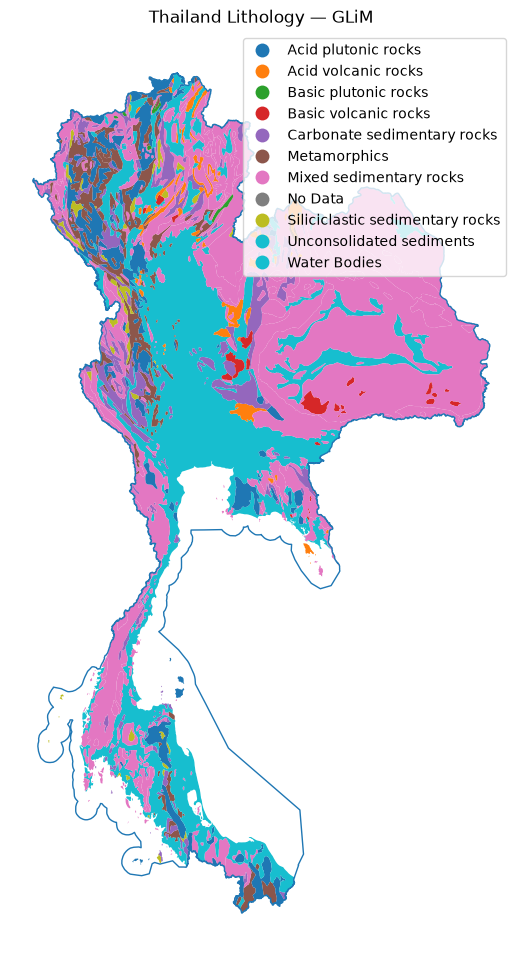

In [53]:
# Visualize Thailand geology when available

if geology_thailand is not None and len(geology_thailand) > 0:
    fig, ax = plt.subplots(figsize=(10, 12))
    geology_thailand.plot(
        column="xx_Description",
        categorical=True,
        legend=True,
        ax=ax
    )
    thailand_boundary.to_crs(geology_thailand.crs).boundary.plot(ax=ax, linewidth=1)
    ax.set_title("Thailand Lithology — GLiM")
    ax.axis("off")
    plt.show()
else:
    print("Geology visualization skipped.")

In [54]:
# Encode geology classes when geology is available

geology_mapping = {}

if geology_thailand is not None and len(geology_thailand) > 0:
    geology_thailand["geology_name"] = (
        geology_thailand["xx_Description"].astype(str).str.strip()
    )

    geology_thailand = geology_thailand[
        geology_thailand["geology_name"] != "No Data"
    ].copy()

    geology_classes = sorted(geology_thailand["geology_name"].dropna().unique())
    geology_mapping = {
        name: code
        for code, name in enumerate(geology_classes, start=1)
    }
    geology_thailand["geologi"] = geology_thailand["geology_name"].map(geology_mapping)

    print("Geology class mapping:")
    for name, code in geology_mapping.items():
        print(f"{code:2d} = {name}")
else:
    print("Geology encoding skipped.")

Geology class mapping:
 1 = Acid plutonic rocks
 2 = Acid volcanic rocks
 3 = Basic plutonic rocks
 4 = Basic volcanic rocks
 5 = Carbonate sedimentary rocks
 6 = Metamorphics
 7 = Mixed sedimentary rocks
 8 = Siliciclastic sedimentary rocks
 9 = Unconsolidated sediments
10 = Water Bodies


In [55]:
# Save geology class legend for reproducibility

GEOLOGY_LEGEND_PATH = PROCESSED_DIR / "thailand_geology_legend.csv"

if geology_mapping:
    geology_legend = pd.DataFrame({
        "geologi": list(geology_mapping.values()),
        "geology_name": list(geology_mapping.keys())
    })
    geology_legend.to_csv(GEOLOGY_LEGEND_PATH, index=False)
    print("Saved geology legend:", GEOLOGY_LEGEND_PATH)
    display(geology_legend)
else:
    print("No geology legend saved because geology is unavailable.")

Saved geology legend: D:\PROJECTS\Landslide_prediction\data\processed\thailand_geology_legend.csv


,geologi,geology_name
0,1,Acid plutonic rocks
1,2,Acid volcanic rocks
2,3,Basic plutonic rocks
3,4,Basic volcanic rocks
4,5,Carbonate sedimentary rocks
5,6,Metamorphics
6,7,Mixed sedimentary rocks
7,8,Siliciclastic sedimentary rocks
8,9,Unconsolidated sediments
9,10,Water Bodies


In [56]:
# Add geology to combined modelling points

if geology_thailand is not None and "geologi" in geology_thailand.columns:
    geology_for_join = geology_thailand[
        ["geologi", "geology_name", "geometry"]
    ].to_crs(combined.crs)

    combined_with_id = combined.reset_index().rename(columns={"index": "point_id"})

    geology_join = gpd.sjoin(
        combined_with_id,
        geology_for_join,
        how="left",
        predicate="within"
    )

    geology_join = (
        geology_join
        .sort_values("point_id")
        .drop_duplicates(subset="point_id")
    )

    geology_values = geology_join.set_index("point_id")["geologi"]
    geology_names = geology_join.set_index("point_id")["geology_name"]

    combined["geologi"] = combined.index.to_series().map(geology_values)
    combined["geology_name"] = combined.index.to_series().map(geology_names)

    print("Valid geology:", combined["geologi"].notna().sum(), "/", len(combined))
    print()
    print("Geology distribution:")
    print(combined["geology_name"].value_counts(dropna=False))
else:
    print("Geology factor skipped.")


Valid geology: 109454 / 109642

Geology distribution:
geology_name
Mixed sedimentary rocks            53050
Unconsolidated sediments           18073
Acid plutonic rocks                16795
Metamorphics                        8951
Carbonate sedimentary rocks         7954
Acid volcanic rocks                 2371
Siliciclastic sedimentary rocks     1452
Basic volcanic rocks                 488
NaN                                  188
Basic plutonic rocks                 183
Water Bodies                         137
Name: count, dtype: int64


In [57]:
# Add geology to the categorical factor list when available

if "geologi" in combined.columns and "geologi" not in categorical_factor_columns:
    categorical_factor_columns.append("geologi")

## 12. Quality control and save the Thailand dataset

In [58]:
# Final factor lists

categorical_factor_columns = []

if "landcover" in combined.columns:
    categorical_factor_columns.append("landcover")

if "geologi" in combined.columns:
    categorical_factor_columns.append("geologi")

model_factor_columns = (
    continuous_factor_columns
    + categorical_factor_columns
)

print("Continuous factors :", continuous_factor_columns)
print("Categorical factors:", categorical_factor_columns)
print("All model factors  :", model_factor_columns)

Continuous factors : ['elev', 'aspect', 'planc', 'profc', 'slope', 'spi', 'twi', 'clay', 'sand', 'soc', 'bdod']
Categorical factors: ['landcover', 'geologi']
All model factors  : ['elev', 'aspect', 'planc', 'profc', 'slope', 'spi', 'twi', 'clay', 'sand', 'soc', 'bdod', 'landcover', 'geologi']


In [59]:
# 20 — Quality-control report

metadata_columns = [
    "location_id",
    "landslide_count",
    "recurrence_proxy_flag",
    "recurrence_class",
    "recurrence_weight",
]

report_columns = metadata_columns + [
    "lslpts", "X", "Y", "geometry", "label", "source"
] + model_factor_columns

print("Rows:", len(combined))

print("\nClass balance:")
print(combined["label"].value_counts())

print("\nMissing values (%):")
print(
    (combined[report_columns].isna().mean() * 100)
    .round(2)
)

print(
    "\nDuplicate modelling geometries:",
    combined.geometry.duplicated().sum()
)

print(
    "Duplicate modelling location IDs:",
    combined["location_id"].duplicated().sum()
)

factor_missing = combined[model_factor_columns].isna().sum()

if factor_missing.any():
    print("\nWARNING — missing factor values:")
    print(factor_missing[factor_missing > 0])
else:
    print("\nAll selected factor values are complete.")

positive_qc = combined.loc[combined["label"] == 1]

print("\nPositive-location record-frequency summary:")
print(positive_qc["landslide_count"].describe())

print("\nRecurrence-proxy class distribution:")
print(positive_qc["recurrence_class"].value_counts())

print("\nFinal continuous factors :", continuous_factor_columns)
print("Final categorical factors:", categorical_factor_columns)
print(
    "\nNOTE: landslide_count / recurrence metadata are NOT included "
    "in model_factor_columns to avoid target/history leakage."
)


Rows: 109642

Class balance:
label
1    54821
0    54821
Name: count, dtype: int64

Missing values (%):
location_id              0.00
landslide_count          0.00
recurrence_proxy_flag    0.00
recurrence_class         0.00
recurrence_weight        0.00
lslpts                   0.00
X                        0.00
Y                        0.00
geometry                 0.00
label                    0.00
source                   0.00
elev                     0.01
aspect                   0.01
planc                    0.01
profc                    0.01
slope                    0.01
spi                      0.01
twi                      0.01
clay                     0.00
sand                     0.00
soc                      0.00
bdod                     0.00
landcover                0.00
geologi                  0.17
dtype: float64

Duplicate modelling geometries: 0
Duplicate modelling location IDs: 0

WARNING — missing factor values:
elev         8
aspect       8
planc        8
profc      

In [60]:
# 21 — Save susceptibility, recurrence, and event-level analysis tables

BASE_COLUMNS = [
    "location_id",
    "landslide_count",
    "recurrence_proxy_flag",
    "recurrence_class",
    "recurrence_weight",
    "lslpts",
    "X",
    "Y",
    "geometry",
    "label",
    "source",
]

FINAL_COLUMNS = BASE_COLUMNS + model_factor_columns

def save_geocsv(gdf, path, columns):
    out = gdf[columns].copy()
    out["geometry"] = out.geometry.to_wkt()
    out.to_csv(path, index=False, encoding="utf-8-sig")
    return path

# ------------------------------------------------------------------
# A. Main unique-location susceptibility dataset
# ------------------------------------------------------------------
FINAL_CSV = PROCESSED_DIR / "training_table_thailand_extended.csv"
FINAL_PARQUET = PROCESSED_DIR / "training_table_thailand_extended.parquet"

save_geocsv(combined, FINAL_CSV, FINAL_COLUMNS)
combined[FINAL_COLUMNS].to_parquet(FINAL_PARQUET, index=False)

# ------------------------------------------------------------------
# B. Landslide-only recurrence / frequency dataset
# ------------------------------------------------------------------
RECURRENCE_CSV = PROCESSED_DIR / "thailand_landslide_recurrence_table.csv"
RECURRENCE_PARQUET = PROCESSED_DIR / "thailand_landslide_recurrence_table.parquet"

recurrence_table = combined.loc[
    combined["label"] == 1,
    [
        "location_id",
        "landslide_count",
        "recurrence_proxy_flag",
        "recurrence_class",
        "recurrence_weight",
        "X",
        "Y",
        "geometry",
    ] + model_factor_columns
].copy()

save_geocsv(
    recurrence_table,
    RECURRENCE_CSV,
    recurrence_table.columns.tolist()
)
recurrence_table.to_parquet(
    RECURRENCE_PARQUET,
    index=False
)

# ------------------------------------------------------------------
# C. Event-level table with location-level conditioning factors
# ------------------------------------------------------------------
# This preserves every original DMR record. Environmental factor values
# repeat within an exact location by design.
#
# Do NOT feed this table directly into an ordinary random binary
# susceptibility split: identical locations would be repeated and could
# leak into both train and test sets.
positive_location_factors = (
    combined.loc[
        combined["label"] == 1,
        ["location_id"] + model_factor_columns
    ]
    .drop_duplicates("location_id")
)

event_analysis = event_inventory.merge(
    positive_location_factors,
    on="location_id",
    how="left",
    validate="many_to_one"
)

EVENT_FACTOR_CSV = (
    PROCESSED_DIR /
    "thailand_landslide_event_level_with_factors.csv"
)

event_analysis_csv = event_analysis.copy()
event_analysis_csv["geometry"] = event_analysis_csv.geometry.to_wkt()
event_analysis_csv.to_csv(
    EVENT_FACTOR_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("Saved susceptibility CSV   :", FINAL_CSV)
print("Saved susceptibility Parquet:", FINAL_PARQUET)
print("Saved recurrence CSV       :", RECURRENCE_CSV)
print("Saved recurrence Parquet   :", RECURRENCE_PARQUET)
print("Saved event-level factors  :", EVENT_FACTOR_CSV)

print("\nMain susceptibility shape :", combined[FINAL_COLUMNS].shape)
print("Recurrence table shape     :", recurrence_table.shape)
print("Event-level table shape    :", event_analysis.shape)

print("\nSusceptibility predictors :", model_factor_columns)
print(
    "Recurrence metadata retained separately:",
    [
        "landslide_count",
        "recurrence_proxy_flag",
        "recurrence_class",
        "recurrence_weight",
    ]
)


Saved susceptibility CSV   : D:\PROJECTS\Landslide_prediction\data\processed\training_table_thailand_extended.csv
Saved susceptibility Parquet: D:\PROJECTS\Landslide_prediction\data\processed\training_table_thailand_extended.parquet
Saved recurrence CSV       : D:\PROJECTS\Landslide_prediction\data\processed\thailand_landslide_recurrence_table.csv
Saved recurrence Parquet   : D:\PROJECTS\Landslide_prediction\data\processed\thailand_landslide_recurrence_table.parquet
Saved event-level factors  : D:\PROJECTS\Landslide_prediction\data\processed\thailand_landslide_event_level_with_factors.csv

Main susceptibility shape : (109642, 24)
Recurrence table shape     : (54821, 21)
Event-level table shape    : (56177, 31)

Susceptibility predictors : ['elev', 'aspect', 'planc', 'profc', 'slope', 'spi', 'twi', 'clay', 'sand', 'soc', 'bdod', 'landcover', 'geologi']
Recurrence metadata retained separately: ['landslide_count', 'recurrence_proxy_flag', 'recurrence_class', 'recurrence_weight']


In [61]:
# ==========================================================
# 22 — Reproducibility manifest
# ==========================================================

from datetime import datetime, timezone
import json


# ----------------------------------------------------------
# Factor source files
# ----------------------------------------------------------

factor_sources = {

    # Terrain
    "elev": str(DEM_UTM),
    "aspect": str(ASPECT),
    "planc": str(PLANC),
    "profc": str(PROFC),
    "slope": str(SLOPE),
    "spi": str(SPI),
    "twi": str(TWI),

    # SoilGrids
    "clay": str(CLAY),
    "sand": str(SAND),
    "soc": str(SOC),
    "bdod": str(BDOD),
}


# ----------------------------------------------------------
# ESA WorldCover
# ----------------------------------------------------------

if (
    "LANDCOVER" in globals()
    and LANDCOVER is not None
    and Path(LANDCOVER).exists()
):
    factor_sources["landcover"] = str(LANDCOVER)


# ----------------------------------------------------------
# Geology
# ----------------------------------------------------------

if (
    "GEOLOGY_RAW_PATH" in globals()
    and GEOLOGY_RAW_PATH is not None
    and Path(GEOLOGY_RAW_PATH).exists()
):
    factor_sources["geologi"] = str(GEOLOGY_RAW_PATH)


# ----------------------------------------------------------
# Optional NDVI
# ----------------------------------------------------------

if (
    "NDVI" in globals()
    and NDVI is not None
    and Path(NDVI).exists()
):
    factor_sources["ndvi"] = str(NDVI)


# ----------------------------------------------------------
# Manifest
# ----------------------------------------------------------

manifest = {

    "created_utc":
        datetime.now(timezone.utc).isoformat(),

    # Source data
    "source_data_dir":
        str(RAW_DIR),

    "source_inventory":
        str(INVENTORY_PATH),

    "inventory_source_type":
        str(INVENTORY_SOURCE_TYPE),

    "preferred_dem_path":
        str(PREFERRED_DEM_PATH),

    "resolved_dem_path":
        str(DEM_RAW_PATH) if DEM_RAW_PATH is not None else None,

    "source_landslide_count":
        int(len(thailand_raw)),

    "unique_modelling_landslide_count":
        int((combined["label"] == 1).sum()),

    "unique_source_landslide_locations":
        int(len(unique_landslide_locations)),

    "locations_with_repeated_records":
        int(unique_landslide_locations["recurrence_proxy_flag"].sum()),

    "maximum_records_at_one_location":
        int(unique_landslide_locations["landslide_count"].max()),

    "recurrence_interpretation":
        (
            "Repeated exact coordinates are preserved as source-record frequency "
            "and treated as a recurrence proxy until DMR event semantics are verified."
        ),

    "recurrence_weight_formula":
        "1 + log1p(max(landslide_count - 1, 0))",

    "recurrence_used_as_standard_predictor":
        False,

    "recurrence_sample_weight_enabled":
        bool(USE_RECURRENCE_SAMPLE_WEIGHT),

    "duplicate_source_locations":
        int(thailand_raw.geometry.duplicated().sum()),

    "pseudo_absence_count":
        int((combined["label"] == 0).sum()),

    "total_samples":
        int(len(combined)),

    # Spatial configuration
    "target_crs":
        TARGET_CRS,

    "target_resolution_m":
        TARGET_RESOLUTION_M,

    "random_state":
        RANDOM_STATE,

    "exclusion_buffer_m":
        EXCLUSION_BUFFER_M,

    # Factors
    "continuous_factors":
        continuous_factor_columns,

    "categorical_factors":
        categorical_factor_columns,

    "total_model_factors":
        len(model_factor_columns),

    "factor_sources":
        factor_sources,

    # SoilGrids metadata
    "soilgrids_product":
        "SoilGrids 2.0",

    "soilgrids_depth":
        "0-5 cm mean",

    "soilgrids_native_resolution_m":
        250,

    "soilgrids_variables": {
        "clay": "Clay content (%)",
        "sand": "Sand content (%)",
        "soc": "Soil organic carbon (g/kg)",
        "bdod": "Bulk density (kg/dm3)"
    },

    # WorldCover metadata
    "worldcover_product":
        "ESA WorldCover 2021 v200",

    "worldcover_native_resolution_m":
        10,

    "worldcover_factor":
        "landcover",

    # Geology metadata
    "geology_product":
        "Global Lithological Map (GLiM)",

    "geology_factor":
        "geologi",

    "geology_type":
        "categorical lithology",

    # Excluded factors
    "factors_excluded": [
        "distriv",
        "distroad"
    ],

    "exclusion_reason": (
        "Distance-to-river and distance-to-road were excluded because "
        "repeated live OSM/Overpass bulk extraction was not reliable "
        "enough for a reproducible nationwide workflow. "
        "No substitute values were fabricated."
    ),
}


# ----------------------------------------------------------
# Save manifest
# ----------------------------------------------------------

MANIFEST_PATH = (
    PROCESSED_DIR /
    "thailand_dataset_manifest.json"
)

MANIFEST_PATH.write_text(
    json.dumps(
        manifest,
        indent=2
    ),
    encoding="utf-8"
)


print(
    json.dumps(
        manifest,
        indent=2
    )
)

print(
    "\nManifest saved:",
    MANIFEST_PATH
)

{
  "created_utc": "2026-09-04T20:05:49.335906+00:00",
  "source_data_dir": "D:\\PROJECTS\\Landslide_prediction\\data\\raw\\Thailand",
  "source_inventory": "D:\\PROJECTS\\Landslide_prediction\\data\\raw\\Thailand\\shp_05010102-\\SHP_05010102 \u0e23\u0e48\u0e2d\u0e07\u0e23\u0e2d\u0e22\u0e41\u0e1c\u0e48\u0e19\u0e14\u0e34\u0e19\u0e16\u0e25\u0e48\u0e21\\LANDSLIDE_INVENTORY_MAP.shp",
  "inventory_source_type": "shapefile",
  "preferred_dem_path": "D:\\PROJECTS\\Landslide_prediction\\data\\raw\\Thailand\\thailand_dem_raw.tif",
  "resolved_dem_path": "D:\\PROJECTS\\Landslide_prediction\\data\\raw\\Thailand\\thailand_dem_raw.tif",
  "source_landslide_count": 56177,
  "unique_modelling_landslide_count": 54821,
  "unique_source_landslide_locations": 54821,
  "locations_with_repeated_records": 1300,
  "maximum_records_at_one_location": 4,
  "recurrence_interpretation": "Repeated exact coordinates are preserved as source-record frequency and treated as a recurrence proxy until DMR event semantics

## 13. Exploratory data analysis (EDA)

In [62]:
# 23 — Load saved dataset for EDA

import matplotlib.pyplot as plt
import seaborn as sns

eda_df = pd.read_csv(FINAL_CSV)

print("Shape:", eda_df.shape)
print("\nClass balance:")
print(eda_df["label"].value_counts())

print("\nMissing factors (%):")
print(
    (eda_df[model_factor_columns].isna().mean() * 100)
    .round(2)
)

eda_df.head()

print("\nPositive-location recurrence / frequency summary:")
positive_eda = eda_df.loc[eda_df["label"] == 1].copy()

display(
    positive_eda[
        ["landslide_count", "recurrence_weight"]
    ].describe().T
)

print("\nRecurrence-proxy classes:")
print(
    positive_eda["recurrence_class"]
    .value_counts()
)

print(
    "\nImportant: recurrence columns are metadata/optional weights, "
    "not ordinary susceptibility predictors."
)


Shape: (109642, 24)

Class balance:
label
1    54821
0    54821
Name: count, dtype: int64

Missing factors (%):
elev         0.01
aspect       0.01
planc        0.01
profc        0.01
slope        0.01
spi          0.01
twi          0.01
clay         0.00
sand         0.00
soc          0.00
bdod         0.00
landcover    0.00
geologi      0.17
dtype: float64

Positive-location recurrence / frequency summary:


,count,mean,std,min,25%,50%,75%,max
landslide_count,54821.0,1.024735,0.161874,1.0,1.0,1.0,1.0,4.000000
recurrence_weight,54821.0,1.016849,0.108864,1.0,1.0,1.0,1.0,2.386294



Recurrence-proxy classes:
recurrence_class
single_record          53521
low_repeat_2_3          1299
moderate_repeat_4_9        1
Name: count, dtype: int64

Important: recurrence columns are metadata/optional weights, not ordinary susceptibility predictors.


In [63]:
# 24 — Descriptive statistics for continuous factors by class

if continuous_factor_columns:
    
    display(
        eda_df
        .groupby("label")[continuous_factor_columns]
        .describe()
        .T
    )


label                  0             1
elev count  54821.000000  54813.000000
     mean     267.752660    579.846410
     std      275.575933    332.790628
     min       -2.624319      8.915945
     25%       74.628532    334.307556
...                  ...           ...
bdod min        0.000000      0.000000
     25%        1.169275      1.105552
     50%        1.269721      1.137964
     75%        1.340232      1.169795
     max        1.554480      1.374347

[88 rows x 2 columns]

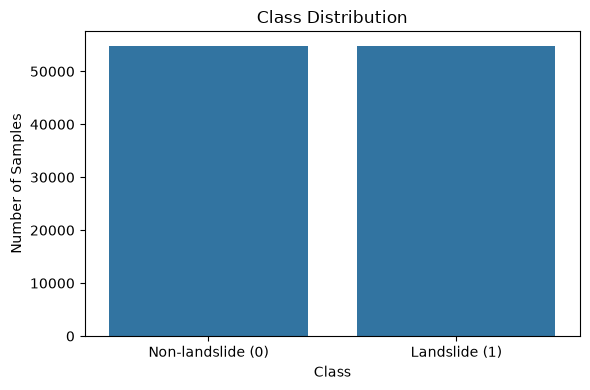

In [64]:
# Class balance visualization

plt.figure(figsize=(6, 4))

sns.countplot(
    data=eda_df,
    x="label"
)

plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")

plt.xticks(
    [0, 1],
    [
        "Non-landslide (0)",
        "Landslide (1)"
    ]
)

plt.tight_layout()
plt.show()

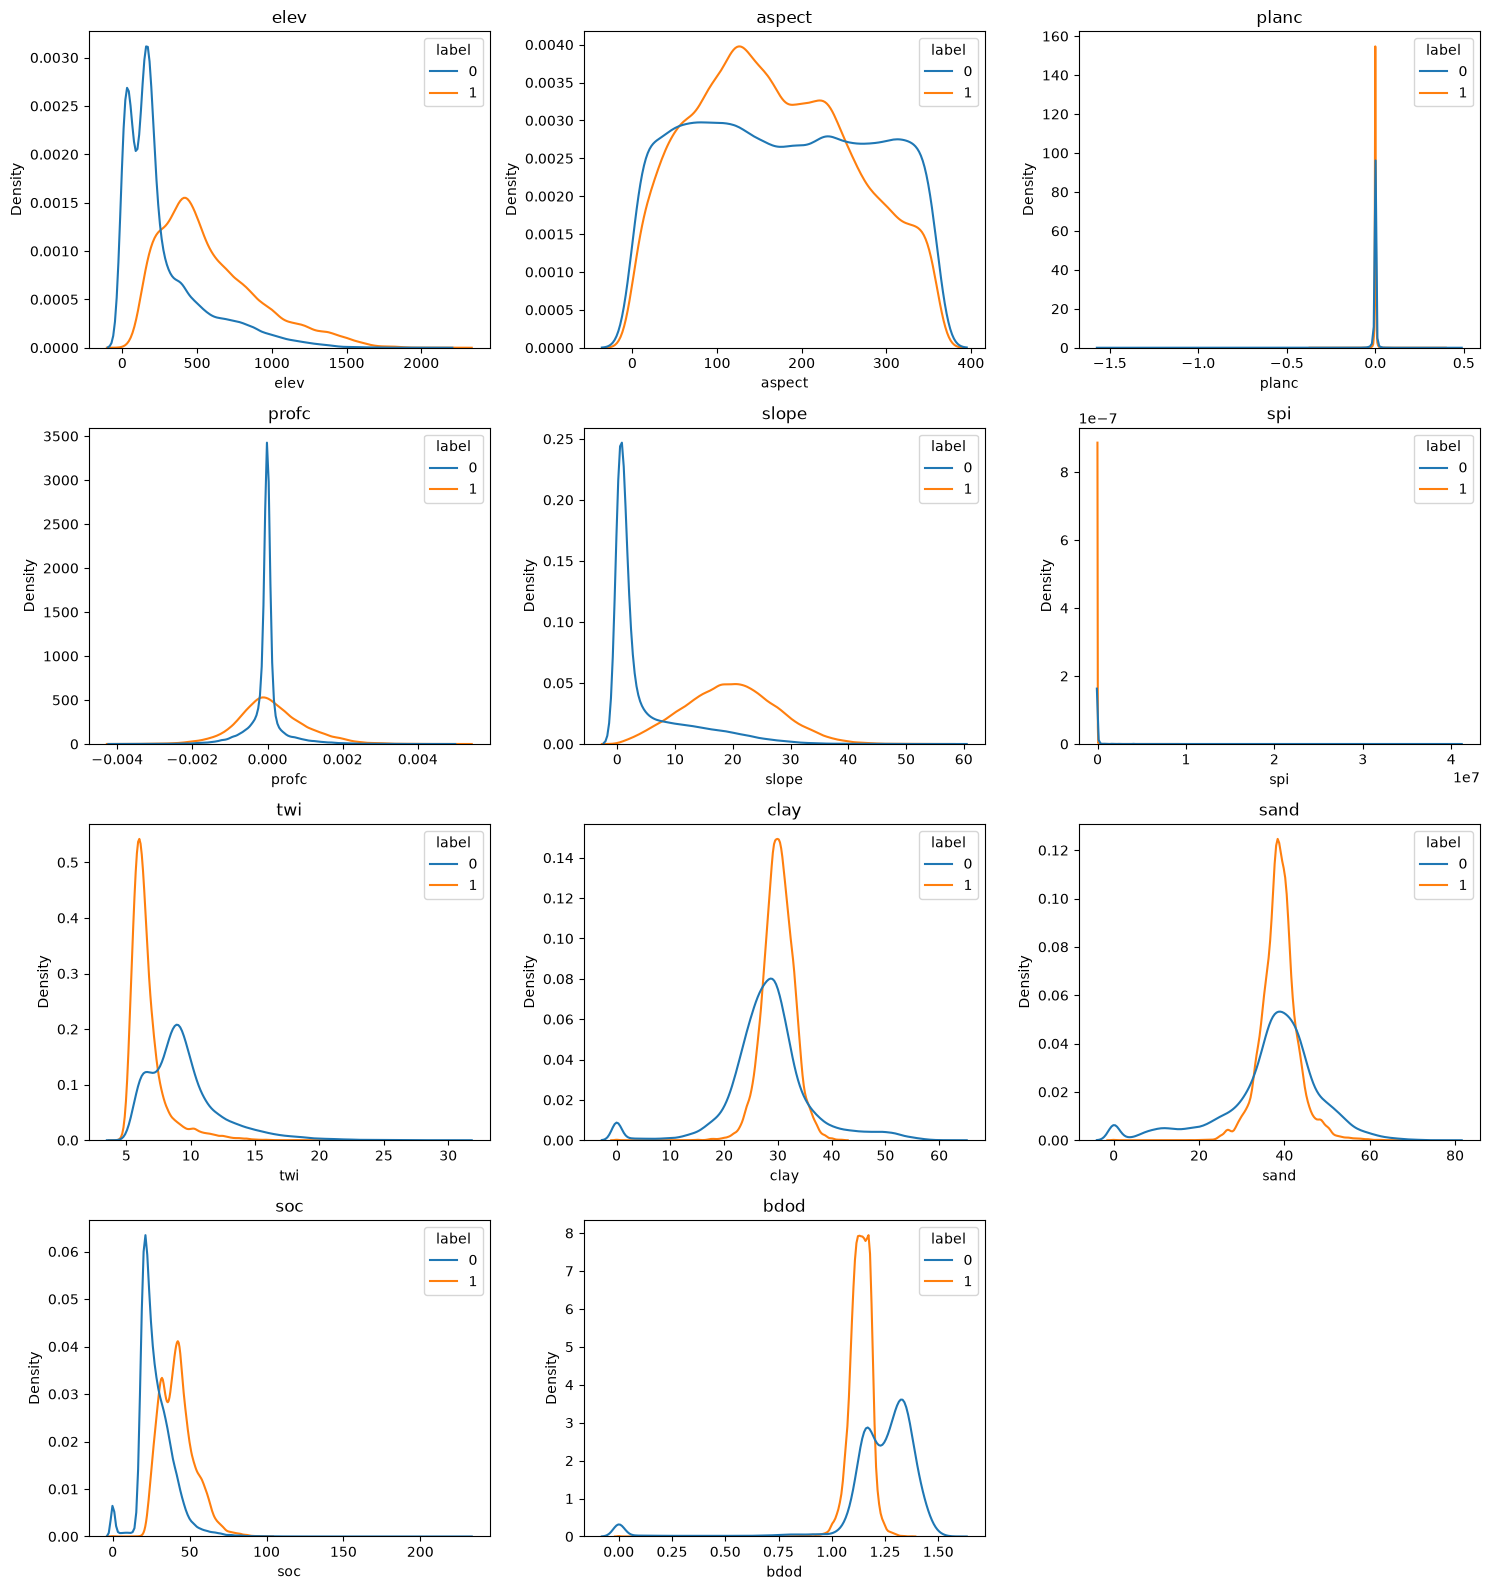

In [65]:
# 25 — Continuous-factor distributions by class

if continuous_factor_columns:
    n = len(continuous_factor_columns)
    ncols = 3
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(15, 4 * nrows)
    )

    axes = np.atleast_1d(axes).flatten()

    for i, col in enumerate(continuous_factor_columns):
        sns.kdeplot(
            data=eda_df,
            x=col,
            hue="label",
            common_norm=False,
            ax=axes[i]
        )
        axes[i].set_title(col)

    for j in range(n, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


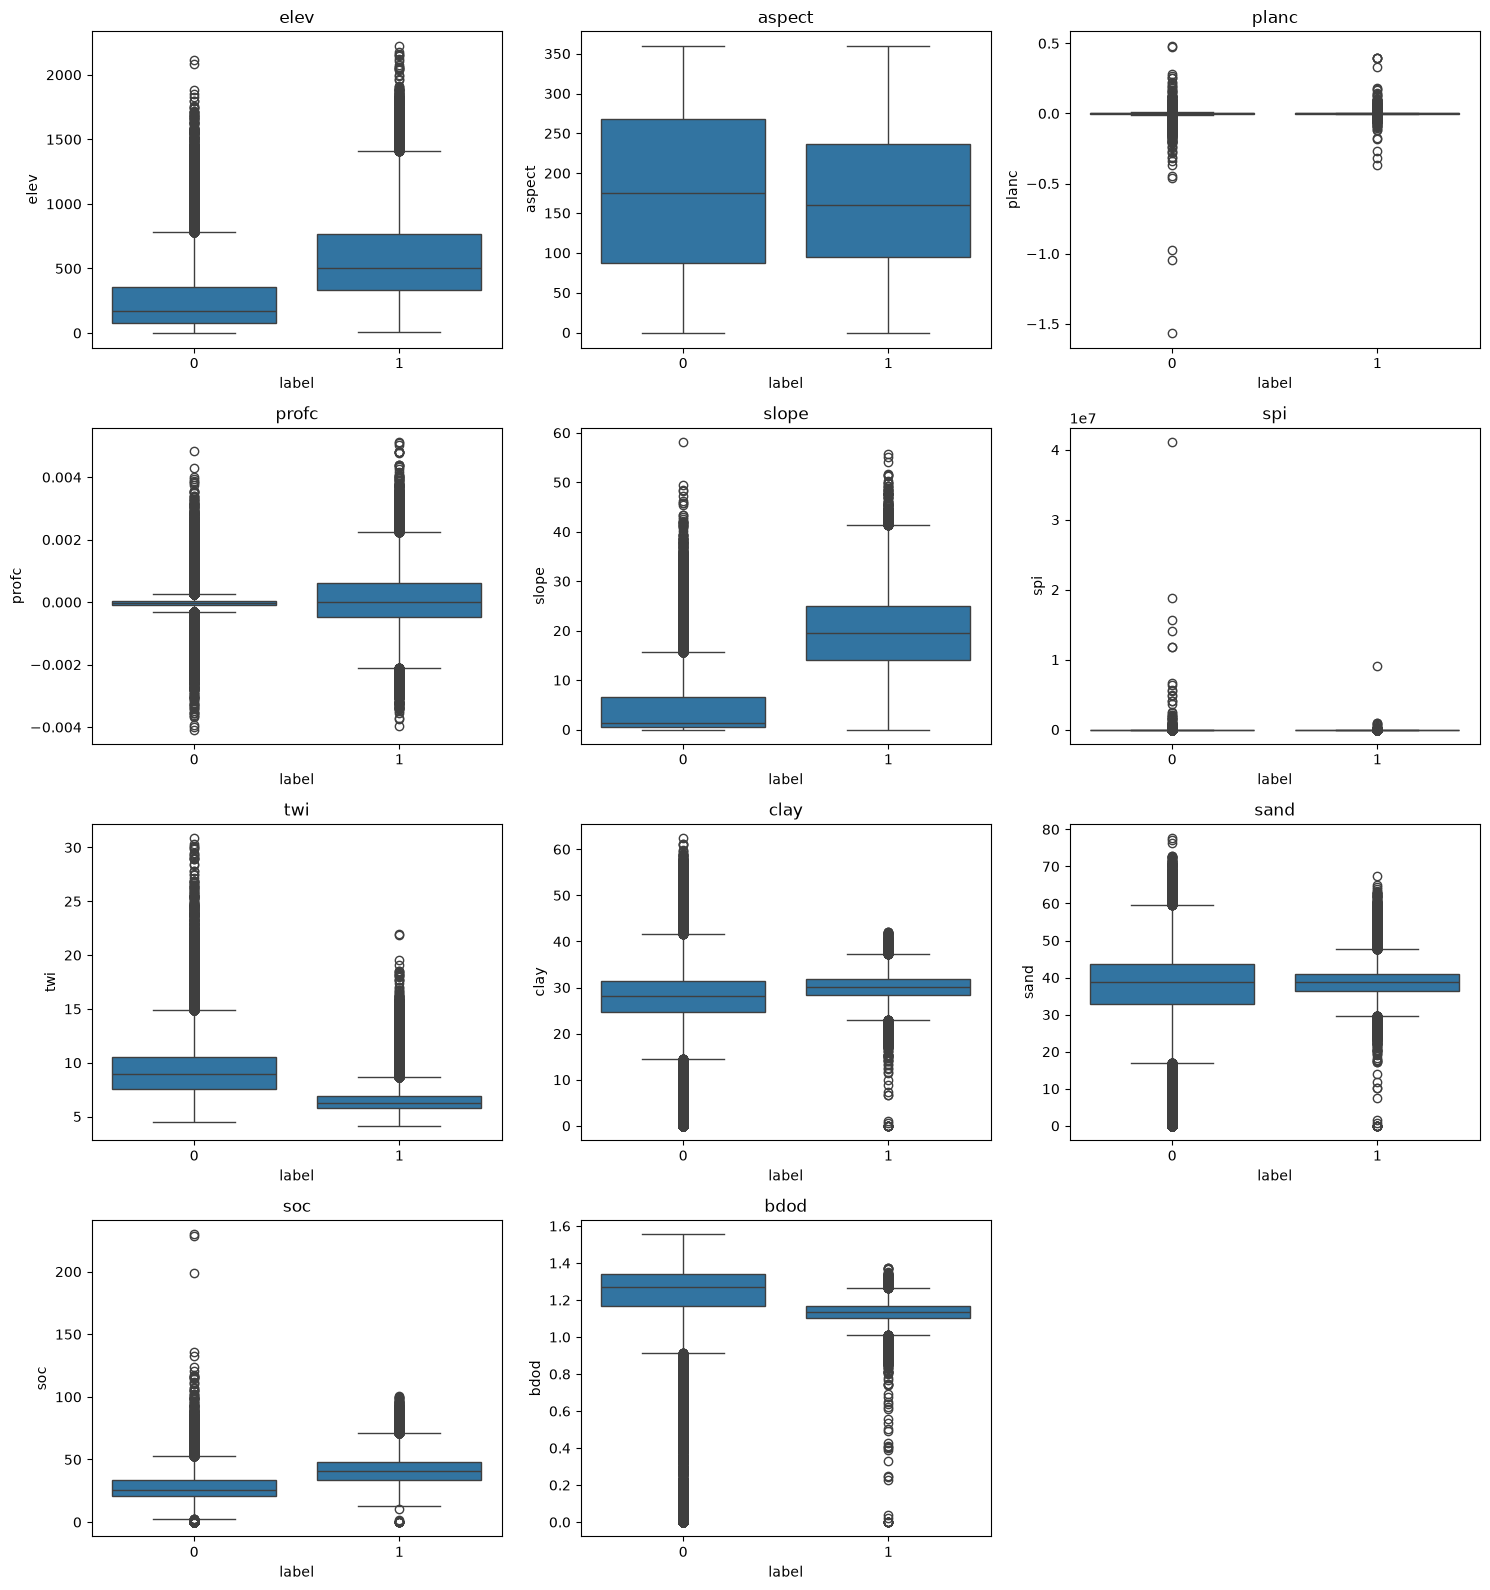

In [66]:
# 26 — Continuous-factor boxplots by class

if continuous_factor_columns:
    n = len(continuous_factor_columns)
    ncols = 3
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(15, 4 * nrows)
    )

    axes = np.atleast_1d(axes).flatten()

    for i, col in enumerate(continuous_factor_columns):
        sns.boxplot(
            data=eda_df,
            x="label",
            y=col,
            ax=axes[i]
        )
        axes[i].set_title(col)

    for j in range(n, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


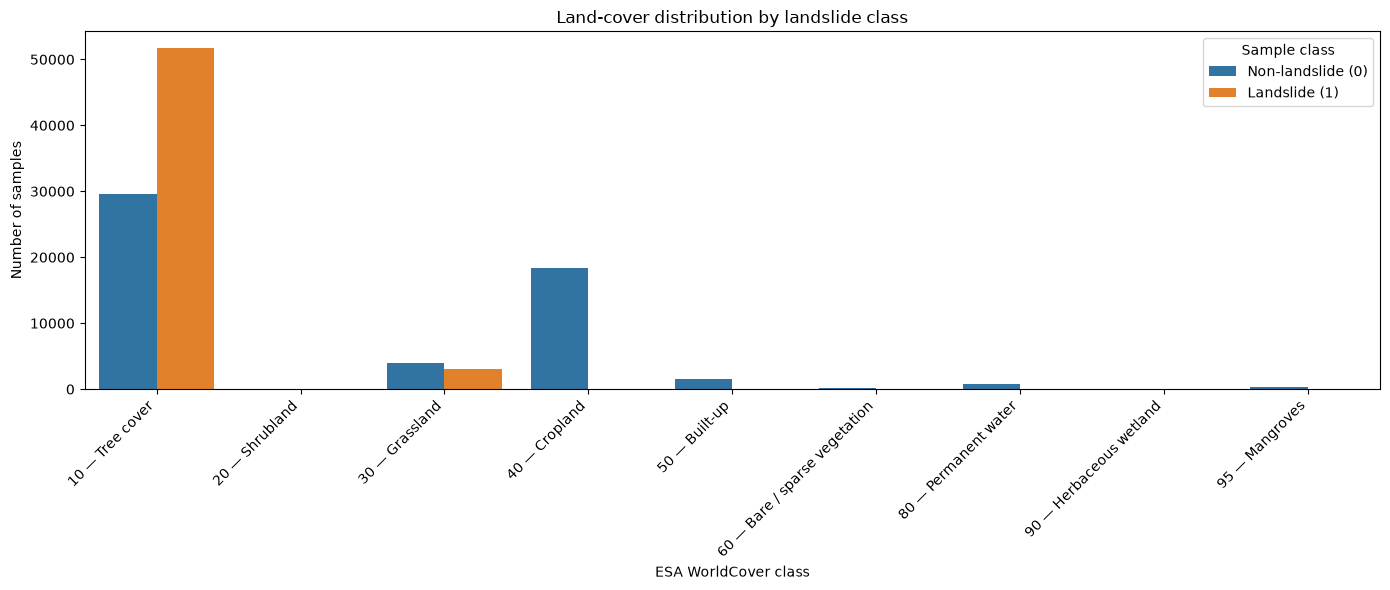

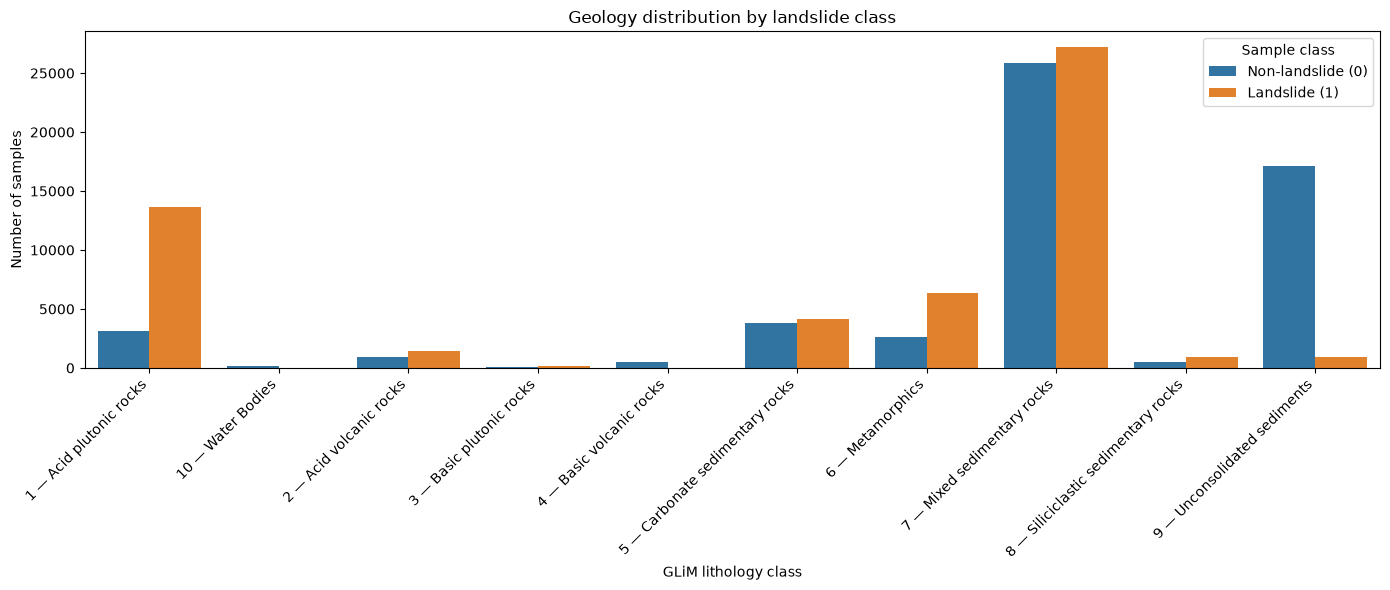

In [67]:
# ==========================================================
# 27 — Categorical factor distributions with class labels
# ==========================================================

# ESA WorldCover class meanings
worldcover_classes = {
    10: "Tree cover",
    20: "Shrubland",
    30: "Grassland",
    40: "Cropland",
    50: "Built-up",
    60: "Bare / sparse vegetation",
    70: "Snow and ice",
    80: "Permanent water",
    90: "Herbaceous wetland",
    95: "Mangroves",
    100: "Moss and lichen",
}


# ----------------------------------------------------------
# Build geology code → name mapping
# ----------------------------------------------------------

# Earlier we created:
#
# geology_mapping =
# {
#     "Acid plutonic rocks": 1,
#     "Metamorphics": 2,
#     ...
# }
#
# Reverse it here so:
#
# 1 → "Acid plutonic rocks"

if "geology_mapping" in globals():

    geology_classes = {
        code: name
        for name, code in geology_mapping.items()
    }

elif "geology_legend" in globals():

    geology_classes = dict(
        zip(
            geology_legend["geologi"],
            geology_legend["geology_name"]
        )
    )

else:

    geology_classes = {}


# ----------------------------------------------------------
# Plot categorical factors
# ----------------------------------------------------------

for col in categorical_factor_columns:

    plot_df = eda_df.copy()


    # --------------------------------------
    # Landcover labels
    # --------------------------------------

    if col == "landcover":

        plot_df["category_label"] = (
            plot_df[col]
            .map(worldcover_classes)
        )

        # Include code + description
        plot_df["category_label"] = (
            plot_df[col]
            .astype("Int64")
            .astype(str)
            + " — "
            + plot_df["category_label"]
        )


    # --------------------------------------
    # Geology labels
    # --------------------------------------

    elif col == "geologi":

        plot_df["category_label"] = (
            plot_df[col]
            .map(geology_classes)
        )

        plot_df["category_label"] = (
            plot_df[col]
            .astype("Int64")
            .astype(str)
            + " — "
            + plot_df["category_label"]
        )


    # --------------------------------------
    # Any other categorical variable
    # --------------------------------------

    else:

        plot_df["category_label"] = (
            plot_df[col]
            .astype(str)
        )


    # Remove missing categories
    plot_df = plot_df.dropna(
        subset=["category_label"]
    )


    # Count categories by landslide class
    counts = (
        plot_df
        .groupby(
            ["category_label", "label"]
        )
        .size()
        .reset_index(name="count")
    )


    # --------------------------------------
    # Plot
    # --------------------------------------

    plt.figure(figsize=(14, 6))

    sns.barplot(
        data=counts,
        x="category_label",
        y="count",
        hue="label"
    )


    if col == "landcover":

        plt.title(
            "Land-cover distribution by landslide class"
        )

        plt.xlabel(
            "ESA WorldCover class"
        )


    elif col == "geologi":

        plt.title(
            "Geology distribution by landslide class"
        )

        plt.xlabel(
            "GLiM lithology class"
        )


    else:

        plt.title(
            f"{col} distribution by class"
        )


    plt.ylabel(
        "Number of samples"
    )


    # Explain label = 0 / 1
    handles, labels = (
        plt.gca()
        .get_legend_handles_labels()
    )

    plt.legend(
        handles,
        [
            "Non-landslide (0)",
            "Landslide (1)"
        ],
        title="Sample class"
    )


    plt.xticks(
        rotation=45,
        ha="right"
    )

    plt.tight_layout()

    plt.show()

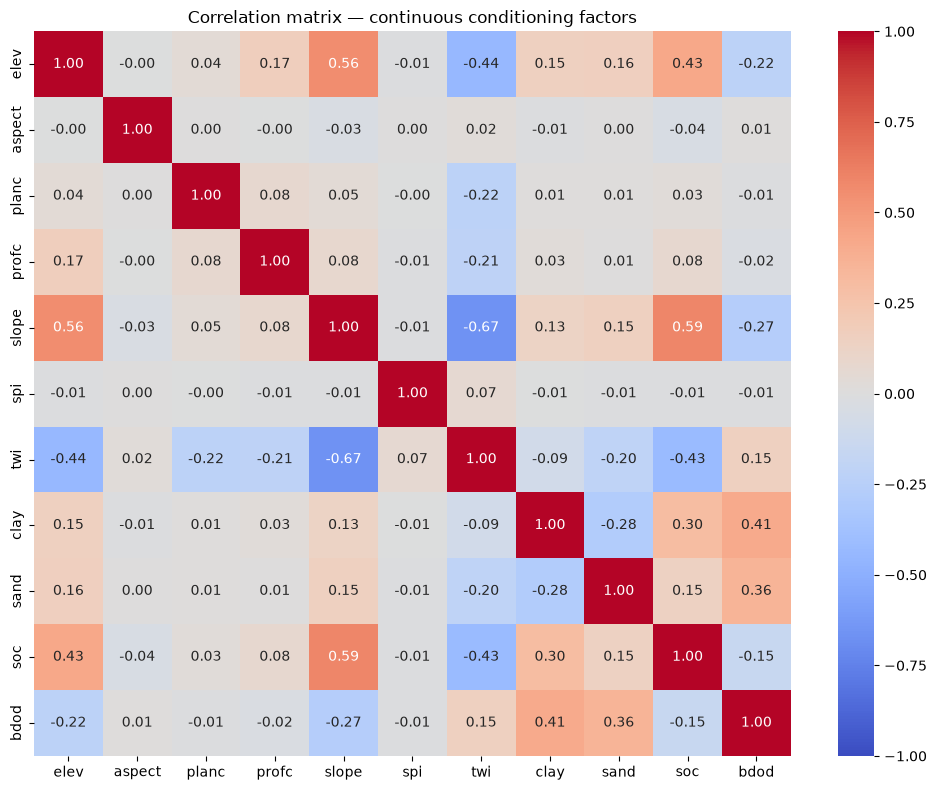

In [68]:
# 28 — Correlation matrix for continuous factors only

if len(continuous_factor_columns) >= 2:
    corr = eda_df[continuous_factor_columns].corr()

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    plt.title("Correlation matrix — continuous conditioning factors")
    plt.tight_layout()
    plt.show()


In [69]:
# 29 — Variance Inflation Factor for continuous factors

from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_df = eda_df[continuous_factor_columns].dropna().copy()

if len(continuous_factor_columns) >= 2 and len(vif_df) > 0:
    vif_data = pd.DataFrame({
        "feature": continuous_factor_columns,
        "VIF": [
            variance_inflation_factor(vif_df.values, i)
            for i in range(len(continuous_factor_columns))
        ]
    })

    display(vif_data.sort_values("VIF", ascending=False))
else:
    print("Not enough continuous factors for VIF.")


,feature,VIF
10,bdod,3.194392
7,clay,3.031955
4,slope,2.678681
8,sand,2.648504
6,twi,2.093659
9,soc,1.988282
0,elev,1.712718
3,profc,1.077592
2,planc,1.073594
5,spi,1.008050


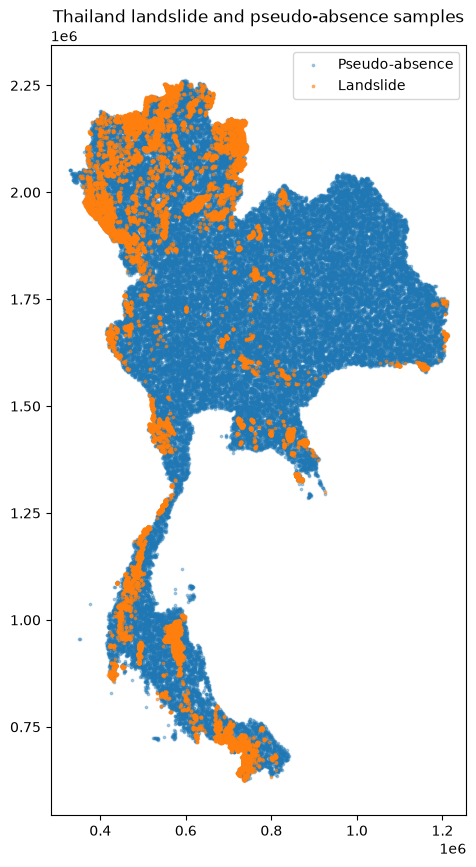

In [70]:
# 30 — Spatial distribution of landslide and pseudo-absence samples

eda_gdf = gpd.GeoDataFrame(
    eda_df.copy(),
    geometry=gpd.GeoSeries.from_wkt(eda_df["geometry"]),
    crs=TARGET_CRS
)

fig, ax = plt.subplots(figsize=(8, 10))

eda_gdf[eda_gdf["label"] == 0].plot(
    ax=ax,
    markersize=3,
    alpha=0.35,
    label="Pseudo-absence"
)

eda_gdf[eda_gdf["label"] == 1].plot(
    ax=ax,
    markersize=3,
    alpha=0.55,
    label="Landslide"
)

ax.legend()
ax.set_title("Thailand landslide and pseudo-absence samples")
plt.show()


In [71]:
# ==========================================================
# Mann–Whitney U test for continuous factors
# ==========================================================

from scipy.stats import mannwhitneyu
import pandas as pd
import numpy as np


mannwhitney_results = []


for col in continuous_factor_columns:

    group_0 = (
        eda_df.loc[
            eda_df["label"] == 0,
            col
        ]
        .dropna()
    )

    group_1 = (
        eda_df.loc[
            eda_df["label"] == 1,
            col
        ]
        .dropna()
    )


    # Mann–Whitney U test
    u_stat, p_value = mannwhitneyu(
        group_0,
        group_1,
        alternative="two-sided"
    )


    # Rank-biserial correlation effect size
    n0 = len(group_0)
    n1 = len(group_1)

    rank_biserial = (
        1 - (2 * u_stat) / (n0 * n1)
    )


    mannwhitney_results.append(
        {
            "Factor": col,

            "Non-landslide median":
                group_0.median(),

            "Landslide median":
                group_1.median(),

            "U statistic":
                u_stat,

            "p-value":
                p_value,

            "Rank-biserial":
                rank_biserial,

            "Significant":
                "Yes" if p_value < 0.05 else "No"
        }
    )


mannwhitney_df = pd.DataFrame(
    mannwhitney_results
)


display(
    mannwhitney_df.round(
        {
            "Non-landslide median": 3,
            "Landslide median": 3,
            "U statistic": 2,
            "p-value": 6,
            "Rank-biserial": 3
        }
    )
)

,Factor,Non-landslide median,Landslide median,U statistic,p-value,Rank-biserial,Significant
0,elev,174.362,500.099,5.801537e+08,0.000000,0.614,Yes
1,aspect,175.487,160.270,1.584914e+09,0.000000,-0.055,Yes
2,planc,0.000,0.000,1.479099e+09,0.000008,0.016,Yes
3,profc,-0.000,0.000,1.417362e+09,0.000000,0.057,Yes
4,slope,1.369,19.628,2.562446e+08,0.000000,0.829,Yes
5,spi,7.635,77.116,5.706242e+08,0.000000,0.620,Yes
6,twi,8.989,6.259,2.554605e+09,0.000000,-0.700,Yes
7,clay,28.186,30.082,1.118048e+09,0.000000,0.256,Yes
8,sand,38.715,38.719,1.482050e+09,0.000083,0.014,Yes
9,soc,25.816,41.173,4.965046e+08,0.000000,0.670,Yes


In [72]:
def interpret_rank_biserial(value):

    value = abs(value)

    if value < 0.10:
        return "Negligible"

    elif value < 0.30:
        return "Small"

    elif value < 0.50:
        return "Moderate"

    else:
        return "Large"


mannwhitney_df[
    "Effect size"
] = mannwhitney_df[
    "Rank-biserial"
].apply(
    interpret_rank_biserial
)


display(
    mannwhitney_df.round(3)
)

,Factor,Non-landslide median,Landslide median,U statistic,p-value,Rank-biserial,Significant,Effect size
0,elev,174.362,500.099,5.801537e+08,0.0,0.614,Yes,Large
1,aspect,175.487,160.270,1.584914e+09,0.0,-0.055,Yes,Negligible
2,planc,0.000,0.000,1.479099e+09,0.0,0.016,Yes,Negligible
3,profc,-0.000,0.000,1.417362e+09,0.0,0.057,Yes,Negligible
4,slope,1.369,19.628,2.562446e+08,0.0,0.829,Yes,Large
5,spi,7.635,77.116,5.706242e+08,0.0,0.620,Yes,Large
6,twi,8.989,6.259,2.554605e+09,0.0,-0.700,Yes,Large
7,clay,28.186,30.082,1.118048e+09,0.0,0.256,Yes,Small
8,sand,38.715,38.719,1.482050e+09,0.0,0.014,Yes,Negligible
9,soc,25.816,41.173,4.965046e+08,0.0,0.670,Yes,Large


In [73]:
# ==========================================================
# Chi-square test + Cramér's V
# for categorical conditioning factors
# ==========================================================

from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np


chi_square_results = []


for col in categorical_factor_columns:

    # Remove missing values
    test_df = eda_df[
        [col, "label"]
    ].dropna()


    # Contingency table
    contingency = pd.crosstab(
        test_df[col],
        test_df["label"]
    )


    # Chi-square test
    chi2, p_value, dof, expected = (
        chi2_contingency(
            contingency
        )
    )


    # Cramér's V
    n = contingency.values.sum()

    rows, cols = (
        contingency.shape
    )

    cramers_v = np.sqrt(
        chi2 /
        (
            n
            * min(
                rows - 1,
                cols - 1
            )
        )
    )


    chi_square_results.append(
        {
            "Factor": col,

            "Chi-square":
                chi2,

            "Degrees of freedom":
                dof,

            "p-value":
                p_value,

            "Cramer's V":
                cramers_v,

            "Significant":
                "Yes"
                if p_value < 0.05
                else "No"
        }
    )


chi_square_df = pd.DataFrame(
    chi_square_results
)


display(
    chi_square_df.round(
        {
            "Chi-square": 3,
            "p-value": 6,
            "Cramer's V": 3
        }
    )
)

,Factor,Chi-square,Degrees of freedom,p-value,Cramer's V,Significant
0,landcover,27069.667,8,0.0,0.497,Yes
1,geologi,23436.091,9,0.0,0.463,Yes


In [74]:
def interpret_cramers_v(value):

    if value < 0.10:
        return "Negligible"

    elif value < 0.30:
        return "Small"

    elif value < 0.50:
        return "Moderate"

    else:
        return "Large"


chi_square_df[
    "Association strength"
] = chi_square_df[
    "Cramer's V"
].apply(
    interpret_cramers_v
)


display(
    chi_square_df.round(3)
)

,Factor,Chi-square,Degrees of freedom,p-value,Cramer's V,Significant,Association strength
0,landcover,27069.667,8,0.0,0.497,Yes,Moderate
1,geologi,23436.091,9,0.0,0.463,Yes,Moderate


In [75]:
# Show categorical contingency tables

for col in categorical_factor_columns:

    print(
        f"\n=============================="
        f"\n{col.upper()}"
        f"\n=============================="
    )

    table = pd.crosstab(
        eda_df[col],
        eda_df["label"],
        margins=True
    )

    display(table)


LANDCOVER


label,0,1,All
landcover,,,
10.0,29557,51672,81229
20.0,43,0,43
30.0,4009,3034,7043
40.0,18368,83,18451
50.0,1509,28,1537
60.0,156,3,159
80.0,821,0,821
90.0,60,0,60
95.0,298,1,299



GEOLOGI


label,0,1,All
geologi,,,
1.0,3171,13624,16795
2.0,911,1460,2371
3.0,61,122,183
4.0,487,1,488
5.0,3811,4143,7954
6.0,2617,6334,8951
7.0,25868,27182,53050
8.0,496,956,1452
9.0,17110,963,18073


## 14. Preprocessing for modelling

Continuous variables are standardized using training data only.

`landcover` (and optional geology) are **categorical**, so they are one-hot encoded rather than treated as continuous numbers.

The notebook saves both the raw train/test splits and the fitted preprocessing object. A later modelling notebook can compare Random Forest, XGBoost, logistic regression, etc.

> For the thesis, a random stratified split is a useful baseline. Spatial cross-validation should also be considered in the modelling stage to evaluate spatial generalization and reduce optimistic estimates caused by spatial autocorrelation.


In [76]:
# 31 — Remove rows with missing selected environmental factors

model_metadata_columns = [
    "location_id",
    "landslide_count",
    "recurrence_proxy_flag",
    "recurrence_class",
    "recurrence_weight",
]

model_df = eda_df[
    model_metadata_columns
    + ["label"]
    + model_factor_columns
].copy()

print("Before dropna:", model_df.shape)

model_df = model_df.dropna(
    subset=model_factor_columns
)

print("After dropna :", model_df.shape)
print("\nClass balance:")
print(model_df["label"].value_counts())

if model_df["location_id"].duplicated().any():
    raise ValueError(
        "Main susceptibility model contains repeated location IDs."
    )

print(
    "\nPredictors intentionally exclude recurrence metadata:",
    model_factor_columns
)


Before dropna: (109642, 19)
After dropna : (109450, 19)

Class balance:
label
1    54781
0    54669
Name: count, dtype: int64

Predictors intentionally exclude recurrence metadata: ['elev', 'aspect', 'planc', 'profc', 'slope', 'spi', 'twi', 'clay', 'sand', 'soc', 'bdod', 'landcover', 'geologi']


In [77]:
# 32 — Report potential continuous-factor outliers- do not silently remove them

for col in continuous_factor_columns:
    q1, q3 = model_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = (
        (model_df[col] < lower) |
        (model_df[col] > upper)
    ).sum()

    print(
        f"{col:12s}: {n_outliers:,} potential outliers "
        "(IQR rule; reported only)"
    )


elev        : 2,896 potential outliers (IQR rule; reported only)
aspect      : 0 potential outliers (IQR rule; reported only)
planc       : 10,858 potential outliers (IQR rule; reported only)
profc       : 16,541 potential outliers (IQR rule; reported only)
slope       : 12 potential outliers (IQR rule; reported only)
spi         : 11,354 potential outliers (IQR rule; reported only)
twi         : 4,283 potential outliers (IQR rule; reported only)
clay        : 7,873 potential outliers (IQR rule; reported only)
sand        : 10,976 potential outliers (IQR rule; reported only)
soc         : 1,301 potential outliers (IQR rule; reported only)
bdod        : 2,486 potential outliers (IQR rule; reported only)


In [78]:
# 33 — Leakage-safe unique-location train/test split

from sklearn.model_selection import train_test_split

# Split ROW INDICES so metadata, labels, factors, and optional
# sample weights stay aligned.
train_idx, test_idx = train_test_split(
    model_df.index.to_numpy(),
    test_size=0.20,
    stratify=model_df["label"],
    random_state=RANDOM_STATE
)

train_df = model_df.loc[train_idx].copy()
test_df = model_df.loc[test_idx].copy()

# Location leakage check.
train_locations = set(train_df["location_id"])
test_locations = set(test_df["location_id"])

overlap = train_locations.intersection(test_locations)

if overlap:
    raise ValueError(
        f"Spatial-location leakage detected: {len(overlap)} "
        "location IDs occur in both train and test."
    )

X_train = train_df[model_factor_columns].copy()
X_test = test_df[model_factor_columns].copy()

y_train = train_df["label"].copy()
y_test = test_df["label"].copy()

# Optional recurrence-aware sample weights.
# Pseudo-absences and single-record landslide locations have weight 1.
# Repeated positive locations receive a damped logarithmic weight.
if USE_RECURRENCE_SAMPLE_WEIGHT:
    sample_weight_train = train_df["recurrence_weight"].astype(float).copy()
    sample_weight_test = test_df["recurrence_weight"].astype(float).copy()
else:
    sample_weight_train = pd.Series(
        1.0,
        index=train_df.index,
        name="recurrence_weight"
    )
    sample_weight_test = pd.Series(
        1.0,
        index=test_df.index,
        name="recurrence_weight"
    )

print("Train:", X_train.shape, y_train.value_counts().to_dict())
print("Test :", X_test.shape, y_test.value_counts().to_dict())
print("Location overlap:", len(overlap))

print("\nTrain recurrence weights:")
print(sample_weight_train.describe())

print(
    "\nUse sample_weight_train only with estimators that support "
    "`sample_weight`. The environmental feature matrix itself does "
    "not contain landslide_count or recurrence_weight."
)


Train: (87560, 13) {1: 43825, 0: 43735}
Test : (21890, 13) {1: 10956, 0: 10934}
Location overlap: 0

Train recurrence weights:
count    87560.000000
mean         1.008406
std          0.077468
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          2.386294
Name: recurrence_weight, dtype: float64

Use sample_weight_train only with estimators that support `sample_weight`. The environmental feature matrix itself does not contain landslide_count or recurrence_weight.


In [79]:
# 34 — Fit preprocessing on TRAIN data only

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

transformers = []

if continuous_factor_columns:
    transformers.append(
        (
            "continuous",
            StandardScaler(),
            continuous_factor_columns
        )
    )

if categorical_factor_columns:
    transformers.append(
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_factor_columns
        )
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed train shape:", X_train_processed.shape)
print("Processed test shape :", X_test_processed.shape)

X_train_processed.head()


Processed train shape: (87560, 30)
Processed test shape : (21890, 30)


,continuous__elev,continuous__aspect,continuous__planc,continuous__profc,continuous__slope,continuous__spi,continuous__twi,continuous__clay,continuous__sand,continuous__soc,...,categorical__geologi_1.0,categorical__geologi_2.0,categorical__geologi_3.0,categorical__geologi_4.0,categorical__geologi_5.0,categorical__geologi_6.0,categorical__geologi_7.0,categorical__geologi_8.0,categorical__geologi_9.0,categorical__geologi_10.0
60800,-1.220453,0.187066,-0.217193,-0.048094,-1.155678,-0.014266,1.160278,2.540598,-2.332957,-1.027475,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
61284,1.252804,1.273693,-0.070914,-0.895604,0.433955,-0.013256,-0.153111,0.104385,0.939266,0.080236,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
31253,0.289244,-0.015043,0.114678,-0.825942,-0.267490,-0.013790,0.012479,0.270798,0.050845,-0.073178,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
103094,-0.098399,-1.499107,0.730489,-0.104217,-1.034661,-0.014257,0.055646,-0.229727,0.718892,-1.014576,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
24455,1.275621,-1.132336,-0.048184,2.436358,1.513903,-0.013757,-0.837640,0.500505,-0.189163,2.227153,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [80]:
# 35 — Save modelling-ready splits, location IDs, weights, and preprocessor

import joblib

# Raw feature splits
X_train.to_csv(PROCESSED_DIR / "X_train_raw.csv", index=False)
X_test.to_csv(PROCESSED_DIR / "X_test_raw.csv", index=False)
y_train.to_csv(PROCESSED_DIR / "y_train.csv", index=False)
y_test.to_csv(PROCESSED_DIR / "y_test.csv", index=False)

# Leakage-audit metadata
train_df[
    [
        "location_id",
        "label",
        "landslide_count",
        "recurrence_proxy_flag",
        "recurrence_class",
        "recurrence_weight",
    ]
].to_csv(
    PROCESSED_DIR / "train_location_metadata.csv",
    index=False
)

test_df[
    [
        "location_id",
        "label",
        "landslide_count",
        "recurrence_proxy_flag",
        "recurrence_class",
        "recurrence_weight",
    ]
].to_csv(
    PROCESSED_DIR / "test_location_metadata.csv",
    index=False
)

sample_weight_train.rename(
    "sample_weight"
).to_csv(
    PROCESSED_DIR / "sample_weight_train.csv",
    index=False
)

sample_weight_test.rename(
    "sample_weight"
).to_csv(
    PROCESSED_DIR / "sample_weight_test.csv",
    index=False
)

# Processed feature splits
X_train_processed.to_csv(
    PROCESSED_DIR / "X_train_processed.csv",
    index=False
)

X_test_processed.to_csv(
    PROCESSED_DIR / "X_test_processed.csv",
    index=False
)

joblib.dump(
    preprocessor,
    PROCESSED_DIR / "preprocessor.pkl"
)

print("Saved modelling-ready train/test data and preprocessor to:")
print(PROCESSED_DIR)
print("\nAlso saved location metadata and optional recurrence sample weights.")


Saved modelling-ready train/test data and preprocessor to:
D:\PROJECTS\Landslide_prediction\data\processed

Also saved location metadata and optional recurrence sample weights.


## Expected Outputs

After all required source datasets are available and the notebook is executed successfully, the main outputs are:

### Automatically downloaded terrain source

* `data/raw/Thailand/thailand_dem_raw.tif` — SRTM1 (~30 m) DEM downloaded automatically when no local DEM is available

### Preserved source/event information

* `thailand_landslide_master.csv` — untouched original DMR inventory attributes with WKT geometry
* `thailand_landslide_master.gpkg` — archival spatial copy of the complete DMR inventory
* `thailand_landslide_events_with_location_id.csv` — every original source row plus unique-location and frequency metadata
* `thailand_landslide_events_with_location_id.gpkg` — spatial version of the enhanced event-level inventory
* `thailand_landslide_unique_locations.csv` — one row per exact landslide coordinate with `landslide_count`
* `thailand_landslide_unique_locations.gpkg` — spatial unique-location inventory

### Susceptibility and recurrence modelling outputs

* `thailand_pseudo_absence_points.gpkg` — reproducibly generated pseudo-absence locations
* `training_table_thailand_extended.csv` — balanced **unique-location** susceptibility dataset
* `training_table_thailand_extended.parquet` — Parquet version of the susceptibility dataset
* `thailand_landslide_recurrence_table.csv` — landslide-only unique locations with frequency/recurrence metadata and factors
* `thailand_landslide_recurrence_table.parquet` — Parquet recurrence table
* `thailand_landslide_event_level_with_factors.csv` — all original DMR rows joined to their location-level conditioning factors
* `sample_weight_train.csv` / `sample_weight_test.csv` — optional logarithmic recurrence weights
* `train_location_metadata.csv` / `test_location_metadata.csv` — audit files for leakage-safe location splitting
* `thailand_dataset_manifest.json` — reproducibility information and recurrence-handling logic
* Raw and processed train-test datasets
* `preprocessor.pkl` — fitted preprocessing pipeline

### Recurrence fields

* `landslide_count` — number of original DMR records at the exact coordinate
* `recurrence_proxy_flag` — `True` when `landslide_count > 1`
* `recurrence_class` — single / low-repeat / moderate-repeat / high-repeat frequency class
* `recurrence_weight` — `1 + log1p(max(landslide_count - 1, 0))`

> `landslide_count` and `recurrence_weight` are deliberately **not included in `model_factor_columns`**. They encode historical inventory frequency and could leak landslide-history information if treated as normal environmental predictors.

### Recommended modelling logic

**Main susceptibility model — where can landslides occur?**

Use one row per unique location:

`environmental conditioning factors → label (1 landslide / 0 pseudo-absence)`

Optionally pass `sample_weight_train` to models that support sample weights. This allows repeatedly recorded landslide locations to receive modest additional importance without repeating identical feature rows many times.

**Recurrence/frequency analysis — where are repeated records concentrated?**

Use `thailand_landslide_recurrence_table.csv` and model either:

* `landslide_count` as a count outcome, or
* `recurrence_class` / `recurrence_proxy_flag` as a classification outcome.

The interpretation should remain **record-frequency / recurrence proxy** unless the DMR metadata confirms that repeated rows represent distinct landslide events.

### Conditioning Factor Families

**Terrain and Hydrological Factors**

* Elevation (`elev`)
* Slope (`slope`)
* Aspect (`aspect`)
* Plan curvature (`planc`)
* Profile curvature (`profc`)
* Topographic Wetness Index (`twi`)
* Stream Power Index (`spi`)

**Soil Factors — SoilGrids 2.0**

* Clay content (`clay`)
* Sand content (`sand`)
* Soil Organic Carbon (`soc`)
* Bulk density (`bdod`)

**Vegetation and Land-Cover Factor**

* ESA WorldCover 2021 land-cover class (`landcover`) when available

**Geological Factor**

* GLiM lithology/geology class (`geologi`) when available

The susceptibility feature matrix remains based on environmental conditioning factors only.
